# S-HAG
**Name:** Dalya Awad Mohammad Hassan

**ID:** 220253121

**Instructor:** Dr. Khalil Abu Zanouna

*Evaluating the Limits of Amdahl’s Law in Heterogeneous Massively Parallel Architectures: A Gustafson-Inspired
Reformulation* — all code of Sections IV–VI.

**How to run (Google Colab):** File → Upload notebook → this file, then **Runtime → Run all**.
Everything runs on the free CPU runtime in a few minutes.

| Part | What it does | Paper |
|---|---|---|
| 1 | Setup | – |
| 2 | S-HAG reference implementation (eqs. (1)–(19)) | IV |
| 3 | Model checks: reductions, P*, bounds; synthetic calibrate-and-predict check; Fig. 1 | IV |
| 4 | Data: download sources, write transcribed tables | V |
| 5 | Build the 218-configuration dataset + 27 consistency checks | V-D |
| 6 | Validation designs E1–E4 | VI-A–D |
| 7 | Refinement tests E5 | VI-C |
| 8 | Figures (overview and paper Figs. 2–4) | VI |
| 9 | Summary tables | VI |
| 10 | Download every output as one zip | – |
| A | Appendix: cluster measurement kit (written to files, not run in Colab) | V-D |

All outputs go to the folder `shag_work/` (`results/`, `figures/`, `data/`).

## 1. Setup

In [ ]:
import os, sys, json, hashlib, importlib, urllib.request, zipfile, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path("shag_work").resolve()
for d in ["model", "data/raw/dle", "data/transcribed", "results", "figures", "kit"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)
print("working folder:", ROOT)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0
working folder: /content/shag_work


## 2. S-HAG reference implementation (Section IV)
Written to `shag_work/model/shag.py` and imported as `M`, because the cluster kit (Appendix) uses the same file.

In [ ]:
%%writefile shag_work/model/shag.py
"""Reference implementation of the revised S-HAG model (Section IV).

Mean-time speedup:
    S(P) = G(P) / D(P)
    G(P) = s0*gs(P) + (1-s0)*gp(P)                     (scaled reference work)
    D(P) = s0*gs(P)/rho_s + (1-s0)*sum_k f_k*gp(P)/H_k(P) * [1 + cv*m(P)] + tau(P) + zeta*m(P)
with
    tau(P) = tau0 + lam*log2(P) + beta*(P-1)            (communication)
    m(P) = E[max of P std normals]; cv = per-worker compute jitter (coefficient of variation),
    zeta = k*sigma_a/T1 additive (OS-noise) jitter accumulated over k synchronisations
All times normalised by T1(W0).
"""
import numpy as np
from scipy.stats import norm
from scipy.optimize import least_squares, brentq


def m_max(P):
    """Expected maximum of P i.i.d. standard normals (Blom approximation); m(1)=0."""
    P = np.asarray(P, dtype=float)
    out = norm.ppf((P - 0.375) / (P + 0.25))
    return np.where(P <= 1, 0.0, out)


def m_max_exact(P):
    """Numerical E[max of P std normals] for checking the approximation."""
    from scipy.integrate import quad
    if P <= 1:
        return 0.0
    f = lambda x: x * P * norm.pdf(x) * norm.cdf(x) ** (P - 1)
    return quad(f, -12, 12, limit=200)[0]


def tau(P, tau0=0.0, lam=0.0, beta=0.0, reference_alone=True):
    """Eq. (4). tau = 0 only for the reference resource executing alone (P = 1 and
    reference_alone=True); any other configuration, including a single non-reference
    device that needs host-device transfers, gets tau0 + lam*log2 P + beta*(P-1)."""
    P = np.asarray(P, dtype=float)
    val = tau0 + lam * np.log2(P) + beta * (P - 1)
    return np.where((P <= 1) & reference_alone, 0.0, val)


def speedup(P, s0, H=None, gs=None, gp=None, rho_s=1.0, phases=None,
            tau0=0.0, lam=0.0, beta=0.0, zeta=0.0, cv=0.0, tau_fn=None):
    """Predicted mean-time speedup. H, gs, gp are callables of P (defaults: P, 1, 1).
    phases: optional list of (f_k, H_k callable) with sum f_k = 1."""
    P = np.asarray(P, dtype=float)
    H = H or (lambda p: p)
    gs = gs or (lambda p: np.ones_like(p))
    gp = gp or (lambda p: np.ones_like(p))
    G = s0 * gs(P) + (1 - s0) * gp(P)
    if phases is None:
        par = (1 - s0) * gp(P) / H(P)
    else:
        par = (1 - s0) * gp(P) * sum(f / Hk(P) for f, Hk in phases)
    t = tau_fn(P) if tau_fn else tau(P, tau0, lam, beta)
    mP = m_max(P)
    D = s0 * gs(P) / rho_s + par * (1 + cv * mP) + t + zeta * mP
    return G / D


def amdahl(P, s):
    return 1.0 / (s + (1 - s) / P)


def gustafson(P, a):
    return P - a * (P - 1)


def usl(P, sigma, kappa):
    return P / (1 + sigma * (P - 1) + kappa * P * (P - 1))


def karp_flatt(S, P):
    return (1 / S - 1 / P) / (1 - 1 / P)


def p_star_log(s, lam):
    """Optimal P for H=P, tau=lam*ln P (natural log)."""
    return (1 - s) / lam


def p_star_lin(s, beta):
    """Optimal P for H=P, tau=beta*(P-1)."""
    return np.sqrt((1 - s) / beta)


def fit(P, S_obs, free=("s0", "lam", "beta", "zeta"), fixed=None, H=None):
    """Least-squares calibration of S-HAG on log-speedup (relative error)."""
    fixed = dict(fixed or {})
    x0 = {"s0": 0.05, "lam": 1e-3, "beta": 1e-5, "zeta": 1e-3, "tau0": 0.0}
    lo = {"s0": 0.0, "lam": 0.0, "beta": 0.0, "zeta": 0.0, "tau0": 0.0}
    hi = {"s0": 1.0, "lam": 1.0, "beta": 1.0, "zeta": 1.0, "tau0": 1.0}

    def pred(x, PP):
        kw = dict(fixed); kw.update(dict(zip(free, x)))
        return speedup(PP, H=H, **kw)

    r = least_squares(lambda x: np.log(pred(x, P)) - np.log(S_obs),
                      [x0[k] for k in free], bounds=([lo[k] for k in free], [hi[k] for k in free]))
    params = dict(zip(free, r.x)); params.update(fixed)
    return params, (lambda PP: pred(r.x, PP))

Writing shag_work/model/shag.py


In [ ]:
sys.path.insert(0, str(ROOT / "model"))
import shag as M
importlib.reload(M)
print("model functions:", [f for f in dir(M) if not f.startswith("_") and callable(getattr(M, f))])

model functions: ['amdahl', 'brentq', 'fit', 'gustafson', 'karp_flatt', 'least_squares', 'm_max', 'm_max_exact', 'norm', 'p_star_lin', 'p_star_log', 'speedup', 'tau', 'usl']


## 3. Model checks (Section IV)
### 3.1 Analytic properties
Reductions to Amdahl, Gustafson, Sun–Ni, USL and Hill–Marty; closed-form P* (18); bound (16); scaled-workload limit (19);
accuracy of the expected-maximum term m(P). Every check is an `assert`.

In [ ]:
def run_model_checks():
    import json
    import numpy as np
    from scipy.optimize import minimize_scalar, least_squares

    rng = np.random.default_rng(7)
    out = {}
    P = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024], float)

    # ---------- 1. reductions ----------
    s = 0.05
    assert np.allclose(M.speedup(P, s), M.amdahl(P, s))
    assert np.allclose(M.speedup(P, s, gp=lambda p: p), M.gustafson(P, s))          # alpha == s0
    G = lambda p: p ** 1.5                                                            # Sun-Ni G(P)
    sunni = (s + (1 - s) * G(P)) / (s + (1 - s) * G(P) / P)
    assert np.allclose(M.speedup(P, s, gp=G), sunni)
    sig, kap = 0.03, 2e-4
    assert np.allclose(M.speedup(P, sig, tau_fn=lambda p: kap * (p - 1)), M.usl(P, sig, kap))
    # Hill-Marty asymmetric: one big core of perf rho (=sqrt(r)), n BCEs, r used by big core
    n, r = 256, 16
    perf = np.sqrt(r)
    hm = 1 / (s / perf + (1 - s) / (perf + n - r))
    assert np.isclose(M.speedup(np.array([n]), s, H=lambda p: perf + p - r, rho_s=perf)[0], hm)
    out["reductions"] = "Amdahl, Gustafson, Sun-Ni, USL, Hill-Marty asymmetric: all exact (allclose)"

    # ---------- 2. bounds and P* ----------
    for s_, lam in [(0.05, 0.002), (0.01, 0.0005), (0.2, 0.01)]:
        f = lambda p: -M.speedup(np.array([p]), s_, tau_fn=lambda q: lam * np.log(q))[0]
        num = minimize_scalar(f, bounds=(1.01, 1e6), method="bounded", options={"xatol": 1e-6}).x
        assert np.isclose(num, M.p_star_log(s_, lam), rtol=1e-3), (num, M.p_star_log(s_, lam))
    for s_, b in [(0.05, 1e-4), (0.01, 1e-6)]:
        f = lambda p: -M.speedup(np.array([p]), s_, beta=b)[0]
        num = minimize_scalar(f, bounds=(1.01, 1e6), method="bounded", options={"xatol": 1e-6}).x
        assert np.isclose(num, M.p_star_lin(s_, b), rtol=1e-3)
    Sx = M.speedup(P, 0.05, H=lambda p: 0.8 * p, lam=0.002, zeta=0.001)
    assert np.all(Sx <= np.minimum(np.maximum(0.8 * P, 1), 1 / 0.05) + 1e-12) and np.all(Sx > 0)
    out["P_star"] = "closed forms (1-s)/lam and sqrt((1-s)/beta) match numerical optimum (rtol 1e-3); bound (8) holds"

    # ---------- 3. noise term ----------
    rows = []
    for p in [2, 8, 64, 512, 4096]:
        ex = M.m_max_exact(p)
        mc = rng.standard_normal((4000, p)).max(1).mean() if p <= 512 else float("nan")
        rows.append((p, ex, float(M.m_max(p)), float(np.sqrt(2 * np.log(p))), mc))
    out["noise_table"] = rows
    for p, ex, bl, sq, mc in rows:
        assert abs(bl - ex) / ex < (0.05 if p == 2 else 0.01)   # Blom: <5% at P=2, <1% beyond
    assert all(sq > ex for p, ex, bl, sq, mc in rows)   # sqrt(2 ln P) overestimates

    # ---------- 4. independent BSP simulator ----------
    def simulate(p, weak=False, hetero=False, reps=15, k=50, Ws=0.02, Wp=0.98,
                 L=4e-5, a2a=1.5e-7, cv=0.05, seed=0):
        """Mean elapsed time (s, normalised by T1(W0)=1) of a BSP job; returns per-rep times."""
        rg = np.random.default_rng(seed + int(p))
        p = int(p)
        rates = np.ones(p)
        if hetero:                                   # every 4th worker is a 6x accelerator
            rates[::4] = 6.0
        work = Wp * (p if weak else 1)
        share = rates / rates.sum()                  # rate-proportional partition (u_i = 1)
        times = []
        for _ in range(reps):
            t = Ws
            for _ in range(k):
                comp = (work / k) * share / rates
                comp = comp * rg.lognormal(-0.5 * cv**2, cv, size=p)   # mean-one jitter
                comm = 0.0 if p == 1 else L * np.ceil(np.log2(p)) + a2a * (p - 1)
                t += comp.max() + comm
            times.append(t)
        return np.array(times)

    def T1(weak, p, hetero):
        # serial reference time of the workload on ONE reference worker (rate 1), no noise
        return 0.02 + 0.98 * (p if weak else 1)

    def run(weak, hetero, cal_max=16):
        # capacity from measured rates (eq. 1): P workers, every 4th is 6x -> H = P + 5*ceil(P/4)
        Hf = (lambda q: np.asarray(q, float) + 5 * np.ceil(np.asarray(q, float) / 4)) if hetero else None
        Sm = np.array([T1(weak, p, hetero) / simulate(p, weak, hetero).mean() for p in P])
        cal = P <= cal_max
        gp = (lambda q: q) if weak else None
        def pred(x, PP):
            s0, lam, beta, zeta = x
            return M.speedup(PP, s0, H=Hf, gp=gp, lam=lam, beta=beta, zeta=zeta)
        r = least_squares(lambda x: np.log(pred(x, P[cal])) - np.log(Sm[cal]),
                          [0.05, 1e-3, 1e-6, 1e-3], bounds=([0, 0, 0, 0], [1, 1, 1, 1]))
        S_shag = pred(r.x, P)
        # baselines fitted to the same calibration points
        if weak:
            a = least_squares(lambda x: np.log(M.gustafson(P[cal], x[0])) - np.log(Sm[cal]), [0.05], bounds=([0], [1])).x[0]
            S_cls = M.gustafson(P, a); cls_name = "Gustafson"
            S_am = M.amdahl(P, a)  # what a strong-scaling (Amdahl) view would predict
        else:
            sa = least_squares(lambda x: np.log(M.amdahl(P[cal], x[0])) - np.log(Sm[cal]), [0.05], bounds=([0], [1])).x[0]
            S_cls = M.amdahl(P, sa); cls_name = "Amdahl"; S_am = S_cls
        su = least_squares(lambda x: np.log(M.usl(P[cal], *x)) - np.log(Sm[cal]), [0.02, 1e-5], bounds=([0, 0], [1, 1])).x
        S_usl = M.usl(P, *su)
        held = ~cal
        mape = lambda S: float(np.mean(np.abs(S[held] - Sm[held]) / Sm[held]) * 100)
        return dict(weak=weak, hetero=hetero, params=dict(zip(["s0", "lam", "beta", "zeta"], map(float, r.x))),
                    measured=Sm.tolist(), shag=S_shag.tolist(), classical=S_cls.tolist(), usl=S_usl.tolist(),
                    amdahl_view=S_am.tolist(), mape_shag=mape(S_shag), mape_classical=mape(S_cls),
                    mape_usl=mape(S_usl), cls_name=cls_name)

    out["experiments"] = [run(False, False), run(False, True), run(True, False), run(True, True)]
    for e in out["experiments"]:
        print(f"weak={e['weak']!s:5} hetero={e['hetero']!s:5}  held-out MAPE  S-HAG {e['mape_shag']:6.2f}%  "
              f"{e['cls_name']} {e['mape_classical']:7.2f}%  USL {e['mape_usl']:7.2f}%   params {e['params']}")
    out["P"] = P.tolist()
    json.dump(out, open(ROOT / "results/section4_model_checks.json", "w"), indent=1, default=float)
    print(json.dumps({k: out[k] for k in ["reductions", "P_star"]}, indent=1))
    for r_ in rows: print("P=%5d exact %.4f blom %.4f sqrt2lnP %.4f mc %.4f" % r_)

    # ---------- 5. properties added in Section IV-D ----------
    from scipy.optimize import minimize_scalar as _ms
    for s_, lam, b in [(0.02, 0.002, 7e-6), (0.05, 0.01, 1e-5), (0.01, 1e-4, 1e-8)]:
        a = lam / np.log(2)
        closed = (-a + np.sqrt(a * a + 4 * b * (1 - s_))) / (2 * b)
        num = _ms(lambda p: -M.speedup(np.array([p]), s_, lam=lam, beta=b)[0], bounds=(1.01, 1e7),
                  method="bounded", options={"xatol": 1e-7}).x
        assert np.isclose(num, closed, rtol=1e-3), (num, closed)
        assert np.isclose(M.p_star_log(s_, lam / np.log(2)), (1 - s_) * np.log(2) / lam)
    # general strong-scaling bound S <= min{max(rho_s, H), rho_s/s0}
    for rho in [0.5, 1, 2]:
        for chi in [0.3, 1, 2.5]:
            Pp = np.array([1, 2, 8, 64, 1024.])
            S_ = M.speedup(Pp, 0.05, H=lambda q: chi * q, rho_s=rho, lam=1e-3, cv=0.05, zeta=1e-4)
            assert np.all(S_ <= np.minimum(np.maximum(rho, chi * Pp), rho / 0.05) + 1e-12)
    # weak scaling with all-to-all term saturates at (1-s0)/beta
    Sw = M.speedup(np.array([1e8]), 0.02, gp=lambda q: q, beta=1e-5)[0]
    assert np.isclose(Sw, 0.98 / 1e-5, rtol=1e-3)
    # weak scaling, log-only comm: grows ~ P/(lam log2 P) (sublinear but unbounded)
    S1, S2 = M.speedup(np.array([1e6, 1e8]), 0.02, gp=lambda q: q, lam=1e-3)
    assert S2 > S1
    print("Section IV-D properties: P* eq.(18), bound eq.(16), weak-scaling limit eq.(19)  -> OK")
    print("figure P* (with noise):", round(_ms(lambda p: -M.speedup(np.array([p]), 0.02, lam=0.002, beta=7e-6, cv=0.05, zeta=1e-4)[0], bounds=(2, 1e5), method="bounded").x, 1),
          " closed-form w/o noise:", int((-(0.002/np.log(2)) + np.sqrt((0.002/np.log(2))**2 + 4*7e-6*0.98)) / (2*7e-6)))


run_model_checks()

weak=False hetero=False  held-out MAPE  S-HAG  10.61%  Amdahl   10.61%  USL   10.61%   params {'s0': 0.03564711264306507, 'lam': 2.477963875674303e-15, 'beta': 3.1399940061112747e-19, 'zeta': 6.242214653547202e-15}
weak=False hetero=True   held-out MAPE  S-HAG   7.62%  Amdahl 1407.45%  USL 1407.45%   params {'s0': 0.02252571683190381, 'lam': 4.633467036533968e-21, 'beta': 5.1734238085157476e-20, 'zeta': 0.004877230260721436}
weak=True  hetero=False  held-out MAPE  S-HAG   0.16%  Gustafson    6.47%  USL   53.62%   params {'s0': 8.308338765782932e-09, 'lam': 0.00035287695860211437, 'beta': 3.6996482222370395e-12, 'zeta': 0.06596195797135918}
weak=True  hetero=True   held-out MAPE  S-HAG   2.17%  Gustafson   45.39%  USL   45.39%   params {'s0': 0.018986428243595817, 'lam': 0.012397151254542093, 'beta': 7.67579727732809e-11, 'zeta': 5.6247486629219434e-11}
{
 "reductions": "Amdahl, Gustafson, Sun-Ni, USL, Hill-Marty asymmetric: all exact (allclose)",
 "P_star": "closed forms (1-s)/lam and 

### 3.2 Synthetic calibrate-small / predict-large check
An independent bulk-synchronous simulator (not the S-HAG formula) generates runs; S-HAG is calibrated at P ≤ 16 and
predicts P up to 1024. Protocol A fits everything end to end; protocol B calibrates component by component.

In [ ]:
def run_synthetic_experiment():
    import json, sys
    import numpy as np
    from scipy.optimize import least_squares

    K = 50                       # supersteps
    WS, WP = 0.02, 0.98          # serial / parallel reference time of W0 (T1(W0) = 1)
    L, A2A = 4e-5, 1.5e-7        # all-reduce latency per tree level, all-to-all cost per peer
    CV, SIG_A = 0.05, 2e-6       # multiplicative jitter cv, additive OS-noise std per superstep
    P_ALL = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024])


    def rates_for(p, hetero):
        r = np.ones(p)
        if hetero:
            r[::4] = 6.0             # every 4th worker is a 6x accelerator
        return r


    def simulate(p, weak, hetero, reps=15, seed=0, work_only=False, comm_only=False):
        """Returns per-rep elapsed times and instrumented phase data."""
        rg = np.random.default_rng(seed * 100003 + p)
        r = rates_for(p, hetero)
        work = 0.0 if comm_only else WP * (p if weak else 1)
        share = r / r.sum()
        tot, ser, comm_t, comp_samples = [], [], [], []
        for _ in range(reps):
            t = 0.0 if comm_only else WS
            ser.append(t); c_sum = 0.0
            for _ in range(K):
                comp = (work / K) * share / r * rg.lognormal(-0.5 * CV**2, CV, p)
                comp = comp + rg.normal(0, SIG_A, p)
                comp = np.maximum(comp, 0)
                comm = 0.0 if (p == 1 or work_only) else L * np.ceil(np.log2(p)) + A2A * (p - 1)
                t += comp.max() + comm; c_sum += comm
                comp_samples.append(comp)
            tot.append(t); comm_t.append(c_sum)
        return dict(T=np.array(tot), serial=np.array(ser), comm=np.array(comm_t),
                    comp=np.array(comp_samples))


    def T1(weak, p):
        return WS + WP * (p if weak else 1)


    def H_from_rates(rates_by_type, hetero):
        # eq. (1) with u_i = 1, using benchmarked rates of each device type
        def H(q):
            q = np.asarray(q, float)
            if not hetero:
                return q * rates_by_type["cpu"]
            n_acc = np.ceil(q / 4)
            return (q - n_acc) * rates_by_type["cpu"] + n_acc * rates_by_type["acc"]
        return H


    def run(weak, hetero, cal_max=16):
        meas = {int(p): simulate(int(p), weak, hetero) for p in P_ALL}
        S_obs = np.array([T1(weak, p) / meas[int(p)]["T"].mean() for p in P_ALL])
        cal, held = P_ALL <= cal_max, P_ALL > cal_max
        gp = (lambda q: np.asarray(q, float)) if weak else None
        mape = lambda S: float(np.mean(np.abs(S[held] - S_obs[held]) / S_obs[held]) * 100)
        maxape = lambda S: float(np.max(np.abs(S[held] - S_obs[held]) / S_obs[held]) * 100)

        # ---- device-rate benchmark (fixed work on one device of each type, 5 reps) ----
        rg = np.random.default_rng(99)
        rb = {"cpu": 1.0 / np.mean(1.0 * rg.lognormal(-0.5 * CV**2, CV, 5))}
        rb["acc"] = 1.0 / np.mean((1 / 6.0) * rg.lognormal(-0.5 * CV**2, CV, 5)) if hetero else None
        H = H_from_rates(rb, hetero)

        # ---- Protocol A: end-to-end fit ----
        def predA(x, PP):
            return M.speedup(PP, x[0], H=H, gp=gp, lam=x[1], beta=x[2], cv=x[3], zeta=x[4])
        rA = least_squares(lambda x: np.log(predA(x, P_ALL[cal])) - np.log(S_obs[cal]),
                           [0.05, 1e-3, 1e-6, 0.01, 1e-4], bounds=([0] * 5, [1] * 5))
        S_A = predA(rA.x, P_ALL)

        # ---- Protocol B: component-wise ----
        m1 = meas[1]
        s0 = float(m1["serial"].mean() / T1(weak, 1))                 # serial-phase timer at P=1
        Pc = np.array([2, 4, 8, 16, 32, 64])                          # comm micro-benchmark
        cm = np.array([simulate(int(p), weak, hetero, reps=5, comm_only=True, seed=3)["comm"].mean()
                       * (1 + np.random.default_rng(int(p)).normal(0, 0.02)) for p in Pc])
        X = np.c_[np.log2(Pc), Pc - 1]
        (lam, beta), *_ = np.linalg.lstsq(X, cm / T1(weak, 1), rcond=None)
        lam, beta = max(lam, 0), max(beta, 0)
        # jitter benchmark: per-worker compute samples at P<=16 -> cv; empty supersteps -> sigma_a
        cvs = []
        for p in [2, 4, 8, 16]:
            c = meas[p]["comp"]                       # rows = supersteps, cols = workers
            cvs.append(float(np.mean(c.std(1) / c.mean(1))))
        cv_hat = float(np.median(cvs))
        noise = simulate(8, False, False, reps=5, comm_only=True, seed=5)["comp"]
        sig_hat = float(noise.std())
        zeta = K * sig_hat / T1(weak, 1)
        S_B = M.speedup(P_ALL, s0, H=H, gp=gp, lam=lam, beta=beta, cv=cv_hat, zeta=zeta)

        # ---- classical baselines on the same calibration points ----
        if weak:
            a = least_squares(lambda x: np.log(M.gustafson(P_ALL[cal], x[0])) - np.log(S_obs[cal]),
                              [0.05], bounds=([0], [1])).x[0]
            S_c, cname = M.gustafson(P_ALL, a), "Gustafson"
        else:
            sa = least_squares(lambda x: np.log(M.amdahl(P_ALL[cal], x[0])) - np.log(S_obs[cal]),
                               [0.05], bounds=([0], [1])).x[0]
            S_c, cname = M.amdahl(P_ALL, sa), "Amdahl"
        su = least_squares(lambda x: np.log(M.usl(P_ALL[cal], *x)) - np.log(S_obs[cal]),
                           [0.02, 1e-5], bounds=([0, 0], [1, 1])).x
        S_u = M.usl(P_ALL, *su)
        return dict(weak=weak, hetero=hetero, cname=cname, P=P_ALL.tolist(), S_obs=S_obs.tolist(),
                    S_A=S_A.tolist(), S_B=S_B.tolist(), S_c=S_c.tolist(), S_u=S_u.tolist(),
                    paramsB=dict(s0=s0, lam=float(lam), beta=float(beta), cv=cv_hat, zeta=zeta),
                    truth=dict(s0=WS / T1(weak, 1), lam=K * L / T1(weak, 1), beta=K * A2A / T1(weak, 1),
                               cv=CV, zeta=K * SIG_A / T1(weak, 1)),
                    mape=dict(B=mape(S_B), A=mape(S_A), classical=mape(S_c), USL=mape(S_u)),
                    maxape=dict(B=maxape(S_B), A=maxape(S_A), classical=maxape(S_c), USL=maxape(S_u)))


    if True:
        res = [run(w, h) for w in (False, True) for h in (False, True)]
        for e in res:
            print(f"{'weak ' if e['weak'] else 'strong'} {'hetero' if e['hetero'] else 'homog '} | held-out MAPE "
                  f"S-HAG(B) {e['mape']['B']:6.2f}%  S-HAG(A) {e['mape']['A']:7.2f}%  "
                  f"{e['cname']:9s} {e['mape']['classical']:7.2f}%  USL {e['mape']['USL']:7.2f}% | maxAPE B {e['maxape']['B']:.2f}%")
            print("   B params", {k: round(v, 6) for k, v in e["paramsB"].items()})
            print("   truth   ", {k: round(v, 6) for k, v in e["truth"].items()})
        json.dump(res, open(ROOT / "results/section4_synthetic_experiment.json", "w"), indent=1)


run_synthetic_experiment()

strong homog  | held-out MAPE S-HAG(B)   1.00%  S-HAG(A)   46.69%  Amdahl      10.67%  USL   10.67% | maxAPE B 1.80%
   B params {'s0': 0.02, 'lam': 0.001982, 'beta': 9e-06, 'cv': 0.042621, 'zeta': 5.9e-05}
   truth    {'s0': 0.02, 'lam': 0.002, 'beta': 7e-06, 'cv': 0.05, 'zeta': 0.0001}
strong hetero | held-out MAPE S-HAG(B)   0.62%  S-HAG(A)    5.23%  Amdahl    1414.18%  USL 1414.18% | maxAPE B 1.76%
   B params {'s0': 0.02, 'lam': 0.001982, 'beta': 9e-06, 'cv': 0.042622, 'zeta': 5.9e-05}
   truth    {'s0': 0.02, 'lam': 0.002, 'beta': 7e-06, 'cv': 0.05, 'zeta': 0.0001}
weak  homog  | held-out MAPE S-HAG(B)   3.94%  S-HAG(A)   21.15%  Gustafson    6.41%  USL   53.77% | maxAPE B 4.46%
   B params {'s0': 0.02, 'lam': 0.001982, 'beta': 9e-06, 'cv': 0.042628, 'zeta': 5.9e-05}
   truth    {'s0': 0.02, 'lam': 0.002, 'beta': 7e-06, 'cv': 0.05, 'zeta': 0.0001}
weak  hetero | held-out MAPE S-HAG(B)   2.49%  S-HAG(A)    2.03%  Gustafson   45.36%  USL   45.36% | maxAPE B 2.89%
   B params {'s0':

### 3.3 Fig. 1 — predicted speedup with illustrative parameters

P* strong homog: 240


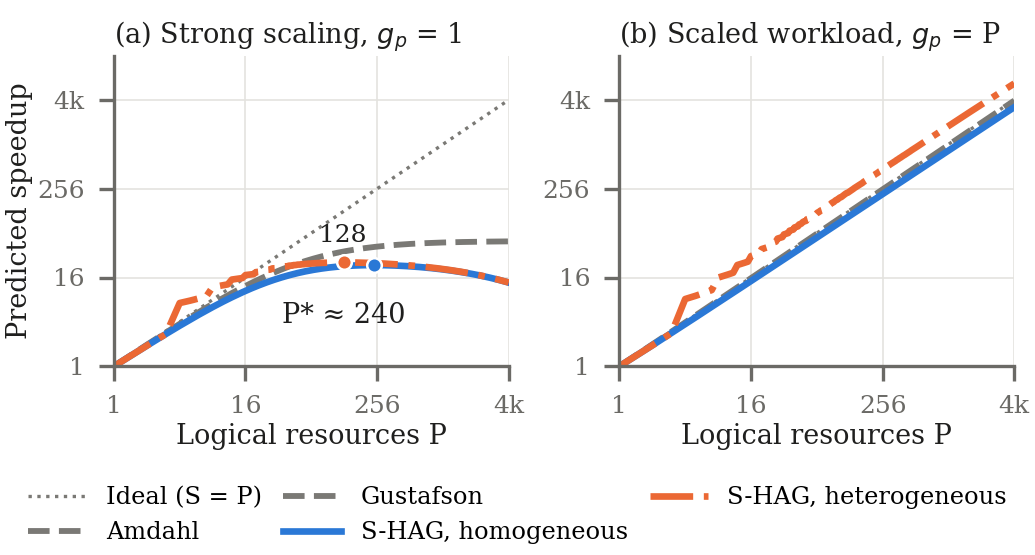

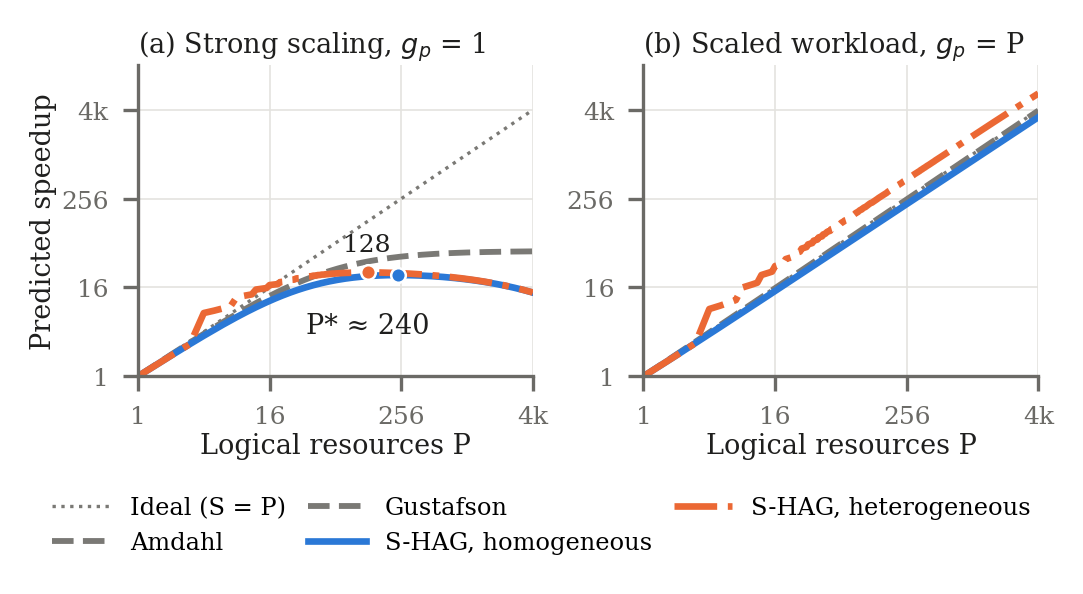

In [ ]:
def make_fig1():
    import numpy as np
    import matplotlib
    import matplotlib.pyplot as plt

    P = np.unique(np.round(np.logspace(0, np.log10(4096), 300)))
    pr = dict(s0=0.02, lam=0.002, beta=7e-6, cv=0.05, zeta=1e-4)
    Hh = lambda q: np.asarray(q, float) + 5 * np.floor(np.asarray(q, float) / 4)  # 1 in 4 units is 6x
    BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#7a7975", "#1f1f1e", "#6b6a66"

    plt.rcParams.update({"font.family": "serif", "font.size": 7.5, "axes.edgecolor": MUTED,
                         "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "xtick.labelsize": 6, "ytick.labelsize": 6, "axes.labelsize": 6.5})
    fig, axs = plt.subplots(1, 2, figsize=(3.45, 1.85), dpi=300)
    panels = [("(a) Strong scaling, g_p = 1", None, M.amdahl(P, pr["s0"]), "Amdahl"),
              ("(b) Scaled workload, g_p = P", lambda q: np.asarray(q, float), M.gustafson(P, pr["s0"]), "Gustafson")]
    for ax, (title, gp, classical, cname) in zip(axs, panels):
        hom = M.speedup(P, H=None, gp=gp, **pr)
        het = M.speedup(P, H=Hh, gp=gp, **pr)
        ax.plot(P, P, color=GRAY, lw=0.8, ls=":", label="Ideal (S = P)")
        ax.plot(P, classical, color=GRAY, lw=1.4, ls="--", label=cname)
        ax.plot(P, hom, color=BLUE, lw=1.6, label="S-HAG, homogeneous")
        ax.plot(P, het, color=ORANGE, lw=1.6, ls="-.", label="S-HAG, heterogeneous")
        if gp is None:
            from scipy.optimize import minimize_scalar
            ps = minimize_scalar(lambda q: -M.speedup(np.array([q]), **pr)[0], bounds=(2, 1e5), method="bounded").x
            Pk, Sk = ps, M.speedup(np.array([ps]), **pr)[0]
            ax.plot(Pk, Sk, "o", ms=3.5, color=BLUE, mec="white", mew=0.6, zorder=5)
            Pi = np.arange(2, 4097); Si = M.speedup(Pi, H=Hh, **pr); j = np.argmax(Si)
            ax.plot(Pi[j], Si[j], "o", ms=3.5, color=ORANGE, mec="white", mew=0.6, zorder=5)
            ax.annotate(f"{int(Pi[j])}", (Pi[j], Si[j]), xytext=(-6, 5), textcoords="offset points", color=INK, fontsize=6)
            ax.annotate(f"P* ≈ {int(round(Pk))}", (Pk, Sk), xytext=(-22, -14),
                        textcoords="offset points", color=INK, fontsize=6.5)
        ax.set_xscale("log", base=2); ax.set_yscale("log", base=2)
        ax.set_xlim(1, 4096); ax.set_ylim(1, 16384)
        ax.set_xticks([1, 16, 256, 4096]); ax.set_xticklabels(["1", "16", "256", "4k"])
        ax.set_yticks([1, 16, 256, 4096]); ax.set_yticklabels(["1", "16", "256", "4k"])
        ax.grid(True, which="major", color="#e4e3df", lw=0.4)
        ax.set_title(title.replace("g_p", "$g_p$"), fontsize=6.5, color=INK, loc="left", pad=3)
        ax.set_xlabel("Logical resources P", labelpad=1)
    axs[0].set_ylabel("Predicted speedup", labelpad=1)
    h, l = axs[0].get_legend_handles_labels()
    h2, l2 = axs[1].get_legend_handles_labels()
    fig.legend([h[0], h[1], h2[1], h[2], h[3]], [l[0], l[1], l2[1], l[2], l[3]], loc="lower center",
               ncol=3, frameon=False, fontsize=5.8, handlelength=2.4, columnspacing=0.9, bbox_to_anchor=(0.5, -0.02))
    fig.subplots_adjust(left=0.11, right=0.98, top=0.9, bottom=0.34, wspace=0.28)
    fig.savefig(ROOT / "figures/fig1_shag.png", dpi=300)
    print("P* strong homog:", int(P[np.argmax(M.speedup(P, **pr))]))


make_fig1()
display(Image(filename=str(ROOT / "figures/fig1_shag.png"), width=600))

## 4. Data (Section V)
### 4.1 Machine-readable sources, downloaded at fixed commits and verified
* LAMMPS timings: `kthare10/lammps-reproducibility`, commit d8f9726 [18]
* BERT-large multi-node tables: `NVIDIA/DeepLearningExamples`, commit 729963d [22]

The MD5 checksums are those of the files analysed for the paper; the cell stops if a download differs.

In [ ]:
LAMMPS = "https://raw.githubusercontent.com/kthare10/lammps-reproducibility/d8f972636d1d312bccf5cc02e89a3e639cba9f83/results/"
DLE = "https://raw.githubusercontent.com/NVIDIA/DeepLearningExamples/729963dd47e7c8bd462ad10bfac7a7b0b604e6dd/"
SOURCES = {
    "data/raw/lammps_fabric_strong.csv": (LAMMPS + "strong-scaling.csv", "d46cf0bb382909dcd6509b157e887087"),
    "data/raw/lammps_fabric_weak.csv":   (LAMMPS + "weak-scaling.csv",   "06a9972ee1309ffc0c95d93d9d09f77f"),
    "data/raw/dle/TF1_BERT_README.md":   (DLE + "TensorFlow/LanguageModeling/BERT/README.md",  "7069441302312ae40086ec6e5fefb541"),
    "data/raw/dle/PyT_BERT_README.md":   (DLE + "PyTorch/LanguageModeling/BERT/README.md",     "c1b460525773813782bef1c2e1529916"),
    "data/raw/dle/TF2_BERT_README.md":   (DLE + "TensorFlow2/LanguageModeling/BERT/README.md", "81e47ee8bbec85e619e2f5d614843885"),
}
for rel, (url, md5) in SOURCES.items():
    path = ROOT / rel
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    got = hashlib.md5(path.read_bytes()).hexdigest()
    if got != md5:
        raise RuntimeError(f"{rel}: checksum {got} differs from the analysed file {md5}")
    print(f"OK  {rel:38s} {path.stat().st_size/1024:7.1f} KB  md5 {got}")

OK  data/raw/lammps_fabric_strong.csv         40.4 KB  md5 d46cf0bb382909dcd6509b157e887087
OK  data/raw/lammps_fabric_weak.csv           32.0 KB  md5 06a9972ee1309ffc0c95d93d9d09f77f
OK  data/raw/dle/TF1_BERT_README.md          118.9 KB  md5 7069441302312ae40086ec6e5fefb541
OK  data/raw/dle/PyT_BERT_README.md           66.0 KB  md5 c1b460525773813782bef1c2e1529916
OK  data/raw/dle/TF2_BERT_README.md           73.4 KB  md5 81e47ee8bbec85e619e2f5d614843885


### 4.2 Transcribed tables (GROMACS, ResNet-50, MPAS-A, CESM); the first line of each file names its source table

In [ ]:
%%writefile shag_work/data/transcribed/cesm_kliphuis2023.csv
# Kliphuis 2023, "Performance, low resolution CESM1/CESM2 on Snellius", technical report, Utrecht University (3 Feb 2023). B1850 fully coupled compset; throughput in model years per 24 h.
version,resolution,cores,sypd,cost_corehours_per_year
CESM1.0.5,f09_g16,128,12.13,254
CESM1.0.5,f09_g16,768,38.39,481
CESM1.0.5,f09_g16,1280,45.61,674
CESM1.0.5,f09_g16,1792,49.99,861
CESM2.1.3,f09_g16,1024,6.24,3938
CESM2.1.3,f09_g16,1280,8.68,3539
CESM2.1.3,f09_g16,1408,9.85,3432
CESM2.1.3,f09_g16,1792,9.41,4570
CESM2.1.3,f09_g16,2304,8.60,6432
CESM1.0.5,f19_g16,768,57.56,321
CESM1.0.5,f19_g16,1024,83.74,295
CESM1.0.5,f19_g16,1536,93.81,393
CESM1.0.5,f19_g16,1664,93.11,429
CESM2.1.3,f19_g16,768,19.42,949
CESM2.1.3,f19_g16,1024,22.54,1091
CESM2.1.3,f19_g16,1280,24.98,1230

Writing shag_work/data/transcribed/cesm_kliphuis2023.csv


In [ ]:
%%writefile shag_work/data/transcribed/gromacs_kutzner2015.csv
# Kutzner et al. 2015, J. Comput. Chem. 36:1990-2008, doi:10.1002/jcc.24030 (arXiv:1507.00898), Tables 11 (MEM, 81,743 atoms) and 12 (RIB, 2,136,412 atoms). GROMACS 4.6. Same cluster: E5-2680v2 2x10 cores, FDR-14 InfiniBand, nodes with no GPU or 2x K20X.
system,node_type,nodes,ns_per_day,efficiency_reported
MEM,cpu,1,26.8,1
MEM,cpu,2,42,0.78
MEM,cpu,4,76.3,0.71
MEM,cpu,8,122,0.57
MEM,cpu,16,162,0.38
MEM,cpu,32,209,0.24
MEM,cpu,64,240,0.14
MEM,gpu_k20x,1,55.2,1
MEM,gpu_k20x,2,74.5,0.67
MEM,gpu_k20x,4,118,0.53
MEM,gpu_k20x,8,163,0.37
MEM,gpu_k20x,16,226,0.26
MEM,gpu_k20x,32,304,0.17
RIB,cpu,1,1.86,1
RIB,cpu,2,3.24,0.87
RIB,cpu,4,6.12,0.82
RIB,cpu,8,12.3,0.83
RIB,cpu,16,21.8,0.73
RIB,cpu,32,39.4,0.66
RIB,cpu,64,70.7,0.59
RIB,cpu,128,128,0.54
RIB,cpu,256,186,0.39
RIB,cpu,512,208,0.22
RIB,gpu_k20x,1,3.99,1
RIB,gpu_k20x,2,5.01,0.63
RIB,gpu_k20x,4,9.53,0.6
RIB,gpu_k20x,8,16.2,0.51
RIB,gpu_k20x,16,27.5,0.43
RIB,gpu_k20x,32,49.1,0.38
RIB,gpu_k20x,64,85.3,0.33
RIB,gpu_k20x,128,129.7,0.25
RIB,gpu_k20x,256,139.5,0.14

Writing shag_work/data/transcribed/gromacs_kutzner2015.csv


In [ ]:
%%writefile shag_work/data/transcribed/mpas_heinzeller2016_D1.csv
# Heinzeller, Duda, Kunstmann 2016, Geosci. Model Dev. 9:77-110, doi:10.5194/gmd-9-77-2016, Table D1: MPAS-A v3.1, 120 km mesh (40,962 cells), 24 h forecast incl. set-up and I/O. Time step 150 s.
machine,nodes,tasks,real_time_s,efficiency_reported_pct
Curie,1,16,1306,100.0
Curie,2,32,633,103.16
Curie,4,64,377,86.6
Curie,6,96,305,71.37
Curie,8,128,269,60.69
Curie,10,160,236,55.34
Curie,12,192,212,51.34
Curie,16,256,187,43.65
Curie,24,384,182,29.9
Curie,32,512,181,22.55
ForHLR1,1,20,863,100.0
ForHLR1,2,40,486,88.79
ForHLR1,3,60,317,90.75
ForHLR1,4,80,255,84.61
ForHLR1,6,120,190,75.7
ForHLR1,8,160,149,72.4
ForHLR1,10,200,135,63.93
ForHLR1,12,240,128,56.18
ForHLR1,16,320,127,42.47
ForHLR1,18,360,131,36.6
ForHLR1,20,400,130,33.19
Juropatest-full,1,28,651,100.0
Juropatest-full,2,56,333,97.75
Juropatest-full,4,112,177,91.95
Juropatest-full,6,168,133,81.58
Juropatest-full,8,224,109,74.66
Juropatest-full,10,280,102,63.82
Juropatest-full,12,336,92,58.97
Juropatest-full,15,420,91,47.69
Juropatest-half,1,14,1172,100.0
Juropatest-half,2,28,628,93.31
Juropatest-half,4,56,317,92.43
Juropatest-half,6,84,220,88.79
Juropatest-half,8,112,167,87.72
Juropatest-half,10,140,142,82.54
Juropatest-half,15,210,95,82.25
Juropatest-half,20,280,87,67.36
Juropatest-half,25,350,88,53.27
Juropatest-half,30,420,99,39.46
Juqueen,32,512,661,100.0
Juqueen,64,1024,477,69.29
Juqueen,96,1536,586,37.6
Juqueen,128,2048,608,27.18
Juqueen,192,3072,751,14.67

Writing shag_work/data/transcribed/mpas_heinzeller2016_D1.csv


In [ ]:
%%writefile shag_work/data/transcribed/mpas_heinzeller2016_T3.csv
# Heinzeller et al. 2016, Table 3: MPAS-A 3 km global mesh (65,536,002 cells) on Juqueen, MPI only, 18 s time step; integration time for 1 h model time (no output).
nodes,tasks,integration_s,efficiency_reported_pct
4096,65536,1760,100.0
8192,131072,960,91.2
16384,262144,490,90.1
24576,393216,335,87.7
28672,458752,360,69.5

Writing shag_work/data/transcribed/mpas_heinzeller2016_T3.csv


In [ ]:
%%writefile shag_work/data/transcribed/resnet50_mikami2018.csv
# Mikami et al. 2018, "Massively Distributed SGD: ImageNet/ResNet-50 Training in a Flash", arXiv:1811.05233, Table 6. ABCI (4x V100 per node, NVLink2, 2x IB EDR per node); 2D-torus all-reduce; 32 images per worker (per-GPU batch fixed).
gpus,images_per_s,efficiency_reported_pct
4,2565,
1024,556522,84.75
2048,1091357,83.10
3456,1641853,74.08
4096,1929054,73.44

Writing shag_work/data/transcribed/resnet50_mikami2018.csv


## 5. Build the dataset and run the consistency checks (Section V-D)

```text
Build the unified S-HAG validation dataset (data/scaling_dataset.csv) from the raw and
transcribed sources, and run internal-consistency checks on every transcribed number.

Each row is one measured configuration of one *series* (same code, input, machine, scaling mode).
Columns:
  series, domain, app, source, machine, unit, mode, P, perf, perf_sd, n_rep, base_P, S_obs
  mode  : strong (fixed workload) | weak (workload grows with P)
  perf  : a rate (higher = faster): 1/time, ns/day, samples/s, model-years/day
  S_obs : strong -> perf(P)/perf(base);  weak -> (P/base_P) * perf_per_unit_work ratio
          = scaled speedup G(p)/[T(p)/T(base)]  (Gustafson definition, eq. (9) with g_p = p)
```

In [ ]:
def build_dataset():
    import re, sys
    from pathlib import Path
    import numpy as np
    import pandas as pd

    RAW, TR = ROOT / "data/raw", ROOT / "data/transcribed"
    rows, checks = [], []


    def add(series, domain, app, source, machine, unit, mode, P, perf, sd=None, nrep=1, extra=None):
        for i, (p, v) in enumerate(zip(P, perf)):
            r = dict(series=series, domain=domain, app=app, source=source, machine=machine, unit=unit,
                     mode=mode, P=float(p), perf=float(v), perf_sd=(None if sd is None else float(sd[i])),
                     n_rep=nrep)
            if extra:
                r.update({k: extra[k][i] for k in extra})
            rows.append(r)


    def check(name, reported, recomputed, tol):
        reported, recomputed = np.asarray(reported, float), np.asarray(recomputed, float)
        ok = np.isfinite(reported)
        dev = np.abs(recomputed[ok] - reported[ok])
        worst = float(dev.max()) if dev.size else 0.0
        checks.append(dict(check=name, n=int(ok.sum()), max_abs_dev=round(worst, 4), tol=tol,
                           passed=bool(worst <= tol)))


    # ---------------- 1. LAMMPS (raw CSV, FABRIC testbed) ----------------
    for mode, f in [("strong", "lammps_fabric_strong.csv"), ("weak", "lammps_fabric_weak.csv")]:
        d = pd.read_csv(RAW / f)
        g = d.groupby(["benchmark", "nprocs"]).agg(t=("loop_time_s", "mean"), sd=("loop_time_s", "std"),
                                                    n=("repeat", "count"), natoms=("natoms", "first"))
        for b, sub in g.groupby(level=0):
            sub = sub.droplevel(0)
            P = sub.index.values
            # perf = atom-steps per second (per unit work for weak scaling)
            perf = 1.0 / sub.t.values
            sd = sub.sd.values / sub.t.values ** 2           # delta-method sd of 1/t
            add(f"LAMMPS-{b.upper()}-{mode}", "Molecular dynamics", "LAMMPS", "FABRIC2026",
                "FABRIC/TACC 32+4x16-core CPU nodes, Ethernet", "core", mode, P, perf, sd, int(sub.n.iloc[0]),
                extra=dict(natoms=sub.natoms.values))
        # consistency: loop_time * timesteps_per_s == nsteps
        check(f"LAMMPS {mode}: loop_time x steps/s = nsteps", d.nsteps, d.loop_time_s * d.timesteps_per_s, 1.0)

    # ---------------- 2. GROMACS (Kutzner et al. 2015) ----------------
    g = pd.read_csv(TR / "gromacs_kutzner2015.csv", comment="#")
    for (sysn, nt), sub in g.groupby(["system", "node_type"]):
        add(f"GROMACS-{sysn}-{nt}", "Molecular dynamics", "GROMACS", "Kutzner2015",
            "E5-2680v2 2x10c, FDR-14 IB" + (", 2x K20X/node" if "gpu" in nt else ""), "node", "strong",
            sub.nodes.values, sub.ns_per_day.values)
        e = sub.ns_per_day.values / (sub.ns_per_day.values[0] * sub.nodes.values)
        check(f"GROMACS {sysn}/{nt}: E = P/(P1 n)", sub.efficiency_reported.values, e, 0.011)

    # ---------------- 3. ResNet-50 (Mikami et al. 2018) ----------------
    r = pd.read_csv(TR / "resnet50_mikami2018.csv", comment="#")
    add("ResNet50-ABCI-weak", "Deep learning", "ResNet-50", "Mikami2018", "ABCI 4x V100/node, 2x EDR IB",
        "GPU", "weak", r.gpus.values, r.images_per_s.values / r.gpus.values)   # per-GPU rate
    e = r.images_per_s / (r.images_per_s[0] / 4 * r.gpus) * 100
    check("ResNet-50: efficiency vs 4-GPU baseline", r.efficiency_reported_pct, e, 0.06)


    # ---------------- 4. BERT-large pre-training (NVIDIA DeepLearningExamples READMEs) ----------------
    def md_table_after(text, heading, ncols_min=5):
        i = text.index(heading)
        lines = text[i:].splitlines()[1:]
        tab, started = [], False
        for ln in lines:
            if ln.strip().startswith("|"):
                started = True
                cells = [c.strip().strip("*") for c in ln.strip().strip("|").split("|")]
                if set("".join(cells)) <= set(":- "):
                    continue
                tab.append(cells)
            elif started:
                break
        hdr, body = tab[0], tab[1:]
        return pd.DataFrame(body, columns=hdr[:len(body[0])] if len(hdr) >= len(body[0]) else None)


    def num(x):
        return float(re.sub(r"[^\d.]", "", str(x)))


    bert_specs = [
        ("TF1_BERT_README.md", "###### Pre-training training performance: multi-node on DGX-2H 32GB",
         "BERT-TF1-DGX2H-V100", "16x V100 32GB/node (DGX-2H)", 16, "Throughput - mixed precision",
         "Weak scaling - mixed precision"),
        ("TF1_BERT_README.md", "###### Pre-training training performance: multi-node on DGX A100 40GB",
         "BERT-TF1-DGXA100", "8x A100 40GB/node (DGX A100)", 8, "Throughput - mixed precision",
         "Weak scaling - mixed precision"),
        ("PyT_BERT_README.md", "###### Pre-training NVIDIA DGX A100 (8x A100 80GB) Multi-node Scaling",
         "BERT-PyT-DGXA100", "8x A100 80GB/node (DGX A100)", 8, "Mixed Precision Throughput",
         "Mixed Precision Strong Scaling"),
        ("TF2_BERT_README.md", "##### Pre-training training performance: Multi-node on NVIDIA DGX-2H V100 (16x V100 32GB)",
         "BERT-TF2-DGX2H-V100", "16x V100 32GB/node (DGX-2H)", 16, "Throughput - mixed precision",
         "Weak scaling - mixed precision"),
        ("TF2_BERT_README.md", "##### Pre-training training performance: Multi-node on NVIDIA DGX A100 (8x A100 80GB)",
         "BERT-TF2-DGXA100", "8x A100/node (DGX A100)", 8, "Throughput - mixed precision",
         "Weak scaling - mixed precision"),
    ]
    for fname, head, sid, mach, gpn, thr_col, sc_col in bert_specs:
        t = (RAW / "dle" / fname).read_text()
        df = md_table_after(t, head)
        nodecol = [c for c in df.columns if c.lower().startswith(("num nodes", "nodes"))][0]
        seqcol = [c for c in df.columns if "sequence" in c.lower()][0]
        for seq, sub in df.groupby(seqcol):
            nodes = sub[nodecol].map(num).values
            thr = sub[thr_col].map(num).values
            order = np.argsort(nodes)
            nodes, thr = nodes[order], thr[order]
            # Global batch is held fixed per optimizer step (gradient accumulation shrinks with nodes),
            # so the work per optimizer step is constant: a strong-scaling series in S-HAG terms,
            # although some READMEs label the column "weak scaling".
            add(f"{sid}-seq{int(num(seq))}", "Deep learning", "BERT-large (Transformer)", "NVIDIA-DLE",
                mach + ", InfiniBand", "node", "strong", nodes, thr)
            check(f"{sid} seq{int(num(seq))}: scaling = thr/thr1", sub[sc_col].map(num).values[order],
                  thr / thr[0], 0.06)

    # ---------------- 5. MPAS-A (Heinzeller et al. 2016) ----------------
    m = pd.read_csv(TR / "mpas_heinzeller2016_D1.csv", comment="#")
    machines = {"Curie": "Curie: Sandy Bridge 2x8c, IB QDR", "ForHLR1": "ForHLR1: Ivy Bridge 2x10c, IB FDR",
                "Juropatest-full": "Juropatest: Haswell 2x14c, IB FDR (28 tasks/node)",
                "Juropatest-half": "Juropatest: Haswell 2x14c, IB FDR (14 tasks/node)",
                "Juqueen": "Juqueen: BlueGene/Q 16c, 5-D torus"}
    for mach, sub in m.groupby("machine", sort=False):
        add(f"MPAS-120km-{mach}", "Climate simulation", "MPAS-A", "Heinzeller2016", machines[mach], "node",
            "strong", sub.nodes.values, 1.0 / sub.real_time_s.values)
        e = sub.real_time_s.values[0] * sub.nodes.values[0] / (sub.real_time_s.values * sub.nodes.values) * 100
        check(f"MPAS D1 {mach}: efficiency", sub.efficiency_reported_pct.values, e, 1.0)
    t3 = pd.read_csv(TR / "mpas_heinzeller2016_T3.csv", comment="#")
    add("MPAS-3km-Juqueen", "Climate simulation", "MPAS-A", "Heinzeller2016", machines["Juqueen"], "node",
        "strong", t3.nodes.values, 1.0 / t3.integration_s.values)
    e = t3.integration_s[0] * t3.nodes[0] / (t3.integration_s * t3.nodes) * 100
    check("MPAS T3 3km: efficiency", t3.efficiency_reported_pct, e, 1.0)

    # ---------------- 6. CESM (Kliphuis 2023, Snellius) ----------------
    c = pd.read_csv(TR / "cesm_kliphuis2023.csv", comment="#")
    for (v, res), sub in c.groupby(["version", "resolution"], sort=False):
        add(f"CESM-{v.split('.')[0]}.{v.split('.')[1]}-{res}", "Climate simulation", "CESM", "Kliphuis2023",
            "Snellius (SURF), B1850 coupled", "core", "strong", sub.cores.values, sub.sypd.values)
        check(f"CESM {v} {res}: cost = 24 x cores / SYPD", sub.cost_corehours_per_year.values,
              24 * sub.cores.values / sub.sypd.values, 6.0)

    # ---------------- assemble ----------------
    D = pd.DataFrame(rows)
    D["base_P"] = D.groupby("series").P.transform("min")
    base_perf = D.groupby("series").perf.transform(lambda s: s.iloc[np.argmin(D.loc[s.index, "P"].values)])
    D["p_rel"] = D.P / D.base_P
    D["S_obs"] = np.where(D["mode"] == "strong", D.perf / base_perf, D.p_rel * D.perf / base_perf)
    D = D.sort_values(["domain", "series", "P"]).reset_index(drop=True)
    D.to_csv(ROOT / "data/scaling_dataset.csv", index=False)
    C = pd.DataFrame(checks)
    C.to_csv(ROOT / "data/consistency_checks.csv", index=False)
    print(D.groupby(["domain", "app"]).agg(series=("series", "nunique"), points=("P", "size")))
    print(f"\n{len(D)} configurations in {D.series.nunique()} series")
    print(C.to_string(index=False))
    if not C.passed.all():
        raise RuntimeError("CONSISTENCY CHECK FAILED")


build_dataset()

                                             series  points
domain             app                                     
Climate simulation CESM                           4      16
                   MPAS-A                         6      49
Deep learning      BERT-large (Transformer)      10      44
                   ResNet-50                      1       5
Molecular dynamics GROMACS                        4      32
                   LAMMPS                         8      72

218 configurations in 33 series
                                           check   n  max_abs_dev   tol  passed
     LAMMPS strong: loop_time x steps/s = nsteps 120       0.0000 1.000    True
       LAMMPS weak: loop_time x steps/s = nsteps  96       0.0000 1.000    True
                   GROMACS MEM/cpu: E = P/(P1 n)   7       0.0037 0.011    True
              GROMACS MEM/gpu_k20x: E = P/(P1 n)   6       0.0048 0.011    True
                   GROMACS RIB/cpu: E = P/(P1 n)  10       0.0039 0.011    True
       

## 6. Validation designs E1–E4 (Section VI)

```text
S-HAG validation protocol (Section V-D) applied to data/scaling_dataset.csv.

For every series (sorted by resource count P):
  * calibration set  = the ceil(n/2) smallest configurations (at least 3); held-out = the rest
  * series with no held-out point (n <= 3) are kept for description only
  * every model is fitted on the calibration set only, by least squares on log speedup,
    and evaluated on the held-out set (extrapolation to larger P)

Models
  Amdahl     S = 1/(s + (1-s)/p)                              1 parameter
  Gustafson  S = p - a(p-1)                     (weak only)   1 parameter
  USL        S = p/(1 + sig(p-1) + kap p(p-1))                2 parameters
  S-HAG-B    eq. (9) with s0 and ONE communication amplitude; the communication FORM is fixed a
             priori from the code's dominant pattern (Table III of Section V):
               halo     -> tau(p) = tau0 for p>1  (piecewise, eq. (4))
               fft      -> tau(p) = beta (p-1)   (all-to-all / PME / PPPM)
               allreduce-> tau(p) = lam log2 p
             weak series use g_s = 1, g_p = p                  2 parameters
  S-HAG-A    (LAMMPS only) component calibration from the code's own timers at calibration P:
             serial = Output+Other at P=1, parallel = Pair+Neigh+Modify+Bond, load-imbalance
             jitter c_v from Pair max/avg, Kspace and Comm fitted as functions of P.  0 fitted
             end-to-end parameters.
  S-HAG-A*   diagnostic only: S-HAG-A with Comm/Kspace taken from the measured held-out runs
             ("oracle communication"), to separate model-structure error from comm extrapolation.
```

In [ ]:
def run_validation():
    import json, sys
    from pathlib import Path
    import numpy as np
    import pandas as pd
    from scipy.optimize import least_squares, nnls


    OUT = ROOT / "results"
    OUT.mkdir(exist_ok=True)
    D = pd.read_csv(ROOT / "data/scaling_dataset.csv")

    COMM_FORM = {  # a priori, from the dominant communication pattern (Section V)
        "LAMMPS-LJ": "halo", "LAMMPS-EAM": "halo", "LAMMPS-RHODO": "fft", "LAMMPS-SPCE": "fft",
        "GROMACS": "fft", "MPAS": "halo", "BERT": "allreduce", "ResNet50": "allreduce", "CESM": "allreduce"}


    def comm_form(series):
        for k, v in COMM_FORM.items():
            if series.startswith(k):
                return v
        raise KeyError(series)


    def tau_fn(form, a, p):
        p = np.asarray(p, float)
        if form == "halo":
            return np.where(p > 1, a, 0.0)
        if form == "fft":
            return a * (p - 1)
        return a * np.log2(p)


    def shag_B(x, p, form, weak):
        s0, a = x
        gp = (lambda q: np.asarray(q, float)) if weak else None
        return M.speedup(p, s0, gp=gp, tau_fn=lambda q: tau_fn(form, a, q))


    def fit(fun, x0, lo, hi, p, S):
        r = least_squares(lambda x: np.log(fun(x, p)) - np.log(S), x0, bounds=(lo, hi))
        return r.x


    def split(n):
        nc = max(3, int(np.ceil(n / 2)))
        return nc


    # ---------- S-HAG-A for LAMMPS (component calibration) ----------
    def lammps_components(mode, bench):
        f = ROOT / f"data/raw/lammps_fabric_{mode}.csv"
        d = pd.read_csv(f)
        d = d[d.benchmark == bench]
        cats = ["pair", "neigh", "comm", "output", "modify", "bond", "kspace"]
        for c in cats:
            d[c] = d[f"{c}_avg_s"].fillna(0.0)
        d["other"] = d.loop_time_s - d[cats].sum(axis=1)
        d["par"] = d.pair + d.neigh + d.modify + d.bond
        d["imb"] = d.pair_max_s / d.pair_avg_s - 1.0
        return d.groupby("nprocs").mean(numeric_only=True)


    def shag_A(mode, bench, P_all, P_cal, oracle=False):
        g = lammps_components(mode, bench)
        one = g.loc[1]
        T1 = one.loop_time_s
        ser = one.output + one.other                      # not reduced by more cores
        par1 = one.par                                    # reduced 1/P (strong) or constant (weak)
        cal = g.loc[[p for p in g.index if p in P_cal]]
        mp = M.m_max(cal.index.values.astype(float))
        ok = mp > 0
        cv = float(np.clip(np.mean(cal.imb.values[ok] / mp[ok]), 0, None)) if ok.any() else 0.0
        Pc = cal.index.values.astype(float)

        def fit_series(y, kind):
            if kind == "kspace" and mode == "strong":
                X = np.c_[1 / Pc, np.log2(Pc), Pc - 1]
            else:
                X = np.c_[np.ones_like(Pc), np.log2(Pc), Pc - 1]
            coef, _ = nnls(X, y)
            return coef

        kc, cc = fit_series(cal.kspace.values, "kspace"), fit_series(cal.comm.values, "comm")
        P = np.asarray(P_all, float)
        if oracle:
            K = g.reindex(P).kspace.values
            C = g.reindex(P).comm.values
        else:
            K = (kc[0] / P if mode == "strong" else kc[0]) + kc[1] * np.log2(P) + kc[2] * (P - 1)
            C = cc[0] + cc[1] * np.log2(P) + cc[2] * (P - 1)
        par = (par1 / P if mode == "strong" else par1) * (1 + cv * M.m_max(P))
        T = ser + par + K + C
        S = T1 / T if mode == "strong" else (P * T1) / T
        params = dict(s0=float(ser / T1), cv=cv, kspace=kc.tolist(), comm=cc.tolist())
        return S, params


    # ---------- main loop ----------
    pred_rows, ser_rows, params_out = [], [], {}
    for sid, s in D.groupby("series", sort=False):
        s = s.sort_values("P")
        p, S, P = s.p_rel.values, s.S_obs.values, s.P.values
        n = len(s)
        weak = s["mode"].iloc[0] == "weak"
        form = comm_form(sid)
        nc = split(n)
        has_heldout = n > nc
        cal = slice(0, nc)
        preds = {}
        am = fit(lambda x, q: M.amdahl(q, x[0]), [0.05], [0], [0.999], p[cal], S[cal])
        preds["Amdahl"] = M.amdahl(p, am[0])
        if weak:
            gu = fit(lambda x, q: M.gustafson(q, x[0]), [0.05], [0], [1], p[cal], S[cal])
            preds["Gustafson"] = M.gustafson(p, gu[0])
        us = fit(lambda x, q: M.usl(q, *x), [0.02, 1e-4], [0, 0], [1, 1], p[cal], S[cal]) if not weak else \
            fit(lambda x, q: M.usl(q, *x), [0.02, 1e-4], [0, 0], [1, 1], p[cal], S[cal])
        preds["USL"] = M.usl(p, *us)
        hb = fit(lambda x, q: shag_B(x, q, form, weak), [0.02, 1e-3], [0, 0], [0.999, 10], p[cal], S[cal])
        preds["S-HAG-B"] = shag_B(hb, p, form, weak)
        pr = {"Amdahl": {"s": am[0]}, "USL": {"sigma": us[0], "kappa": us[1]},
              "S-HAG-B": {"s0": hb[0], "comm_amp": hb[1], "form": form}}
        if weak:
            pr["Gustafson"] = {"alpha": gu[0]}
        if sid.startswith("LAMMPS"):
            bench = sid.split("-")[1].lower()
            mode = "weak" if weak else "strong"
            preds["S-HAG-A"], pr["S-HAG-A"] = shag_A(mode, bench, P, P[cal])
            preds["S-HAG-A* (diag.)"], _ = shag_A(mode, bench, P, P[cal], oracle=True)
        params_out[sid] = {k: {kk: (float(vv) if not isinstance(vv, (str, list)) else vv)
                               for kk, vv in v.items()} for k, v in pr.items()}
        for i in range(n):
            for mname, v in preds.items():
                pred_rows.append(dict(series=sid, P=P[i], p_rel=p[i], role="cal" if i < nc else "held-out",
                                      model=mname, S_obs=S[i], S_pred=float(v[i])))
        if has_heldout:
            h = slice(nc, n)
            for mname, v in preds.items():
                ape = np.abs(v[h] - S[h]) / S[h] * 100
                ser_rows.append(dict(series=sid, domain=s.domain.iloc[0], app=s.app.iloc[0],
                                     mode=s["mode"].iloc[0], comm_form=form, n=n, n_cal=nc, n_held=n - nc,
                                     P_cal_max=P[nc - 1], P_max=P[-1], model=mname, MAPE=ape.mean(),
                                     maxAPE=ape.max(), signed_err_at_Pmax=(v[-1] - S[-1]) / S[-1] * 100,
                                     obs_peak_P=P[np.argmax(S)], pred_peak_P=P[np.argmax(v)]))

    pred = pd.DataFrame(pred_rows)
    res = pd.DataFrame(ser_rows)
    pred.to_csv(OUT / "predictions.csv", index=False)
    res.to_csv(OUT / "per_series_accuracy.csv", index=False)
    json.dump(params_out, open(OUT / "fitted_parameters.json", "w"), indent=1)

    # ---------- heterogeneity case: GROMACS CPU-calibrated model predicts GPU nodes ----------
    het = []
    for sysn in ["MEM", "RIB"]:
        cpu = D[D.series == f"GROMACS-{sysn}-cpu"].sort_values("P")
        gpu = D[D.series == f"GROMACS-{sysn}-gpu_k20x"].sort_values("P")
        nc = split(len(cpu))
        pc, Sc = cpu.p_rel.values, cpu.S_obs.values
        hb = fit(lambda x, q: shag_B(x, q, "fft", False), [0.02, 1e-3], [0, 0], [0.999, 10], pc[:nc], Sc[:nc])
        am = fit(lambda x, q: M.amdahl(q, x[0]), [0.05], [0], [0.999], pc[:nc], Sc[:nc])
        us = fit(lambda x, q: M.usl(q, *x), [0.02, 1e-4], [0, 0], [1, 1], pc[:nc], Sc[:nc])
        chi_obs = gpu.perf.values[0] / cpu.perf.values[0]          # single-node benchmark only
        s0, beta = hb
        chi_eff = (1 - s0) / (1 / chi_obs - s0)                      # capacity of the parallel part
        n = gpu.P.values
        S_obs = gpu.perf.values / cpu.perf.values[0]                 # relative to 1 CPU node
        S_shag = 1.0 / (s0 + (1 - s0) / (chi_eff * n) + beta * (n - 1))
        S_amd = chi_obs * M.amdahl(n, am[0])                         # "a GPU node is chi times a CPU node"
        S_usl = chi_obs * M.usl(n, *us)
        for i in range(len(n)):
            het.append(dict(system=sysn, nodes=n[i], S_obs=S_obs[i], S_HAG=S_shag[i], Amdahl_x_chi=S_amd[i],
                            USL_x_chi=S_usl[i], chi_obs=chi_obs, chi_eff=chi_eff, s0=s0, beta=beta,
                            cpu_cal_nodes_max=cpu.P.values[nc - 1]))
    het = pd.DataFrame(het)
    het.to_csv(OUT / "heterogeneity_gromacs.csv", index=False)

    # ---------- weak-scaling check of the abstract's claim (Amdahl underestimation factor) ----------
    uf = []
    for b in ["LJ", "EAM", "RHODO", "SPCE"]:
        st = D[D.series == f"LAMMPS-{b}-strong"].sort_values("P")
        wk = D[D.series == f"LAMMPS-{b}-weak"].sort_values("P")
        nc = split(len(st))
        am = fit(lambda x, q: M.amdahl(q, x[0]), [0.05], [0], [0.999], st.p_rel.values[:nc], st.S_obs.values[:nc])
        for _, r in wk.iterrows():
            a = M.amdahl(r.p_rel, am[0])
            uf.append(dict(benchmark=b, P=r.P, S_scaled_obs=r.S_obs, Amdahl_fixed_size=a,
                           ratio_obs_over_amdahl=r.S_obs / a, s_amdahl=am[0]))
    pd.DataFrame(uf).to_csv(OUT / "amdahl_weak_underestimation.csv", index=False)

    # ---------- summary ----------
    summ = res.groupby(["domain", "model"]).MAPE.median().unstack()
    print("Median held-out MAPE (%) by domain and model\n", summ.round(1).to_string())
    print("\nSeries evaluated:", res.series.nunique(), " (descriptive only:",
          D.series.nunique() - res.series.nunique(), ")")
    wins = res.loc[res.groupby("series").MAPE.idxmin()].model.value_counts()
    print("\nBest model per series:\n", wins.to_string())
    print("\nHeterogeneity (GROMACS, held-out = all GPU-node runs):")
    for sysn, h in het.groupby("system"):
        e = lambda c: (np.abs(h[c] - h.S_obs) / h.S_obs * 100).mean()
        print(f"  {sysn}: MAPE S-HAG {e('S_HAG'):.1f}%  Amdahl x chi {e('Amdahl_x_chi'):.1f}%  "
              f"USL x chi {e('USL_x_chi'):.1f}%   chi_obs={h.chi_obs.iloc[0]:.2f}")


run_validation()

Median held-out MAPE (%) by domain and model
 model               Amdahl  Gustafson  S-HAG-A  S-HAG-A* (diag.)  S-HAG-B   USL
domain                                                                         
Climate simulation    16.7        NaN      NaN               NaN     18.2  16.7
Deep learning          4.7       13.7      NaN               NaN      4.7   5.5
Molecular dynamics    23.5       39.9     18.0               8.7     25.2  23.5

Series evaluated: 32  (descriptive only: 1 )

Best model per series:
 model
Amdahl              15
USL                  7
S-HAG-A* (diag.)     5
S-HAG-B              3
S-HAG-A              2

Heterogeneity (GROMACS, held-out = all GPU-node runs):
  MEM: MAPE S-HAG 12.9%  Amdahl x chi 29.7%  USL x chi 29.7%   chi_obs=2.06
  RIB: MAPE S-HAG 34.5%  Amdahl x chi 34.2%  USL x chi 34.2%   chi_obs=2.15


## 7. Refinement tests E5 (Section VI-C)
### 7.1 Halo term and FFT-work growth

```text
Test of two proposed refinements of S-HAG on the existing data (all variants tried are reported).

Improvement 2 - halo term that shrinks with P (surface-to-volume), strong scaling:
    tau_halo(P) = gamma * (P_ref/P)^(2/3)   added to the communication basis
  * S-HAG-A (LAMMPS LJ, EAM, rhodopsin, SPC/E strong): Comm timer fitted with basis
      {1, log2P, P-1}            (current)   vs   {1, log2P, P-1, P^(-2/3)}   (improved)
  * S-HAG-B (halo codes: LAMMPS LJ/EAM, MPAS; end-to-end calibration):
      B   : s0, tau0*[p>1]                          (current, 2 parameters)
      B-h2: s0, gamma*[p>1]*p^(-2/3)                (2 parameters, same budget as USL)
      B-h3: s0, tau0*[p>1] + gamma*[p>1]*p^(-2/3)   (3 parameters)

Improvement 3 - phase-specific workload growth for FFT solvers under weak scaling:
    per-rank FFT compute grows with log(N), N proportional to P:
    K_compute(P) = K1 * log2(n1*P)/log2(n1)   (n1 = atoms at P=1, a proxy for FFT grid points)
  * S-HAG-A (LAMMPS rhodopsin, SPC/E weak): Kspace basis
      {1, log2P, P-1}                          (current)   vs
      {log2(n1 P)/log2(n1), log2P, P-1}        (improved)
Calibration/held-out split identical to validate.py (E1).
```

In [ ]:
def run_refinements_2_3():
    import sys
    from pathlib import Path
    import numpy as np
    import pandas as pd
    from scipy.optimize import least_squares, nnls


    D = pd.read_csv(ROOT / "data/scaling_dataset.csv")
    split = lambda n: max(3, int(np.ceil(n / 2)))
    mape = lambda pred, obs: float(np.mean(np.abs(pred - obs) / obs) * 100)
    rows = []


    # ---------------- S-HAG-A variants (LAMMPS component timers) ----------------
    def comp(mode, bench):
        d = pd.read_csv(ROOT / f"data/raw/lammps_fabric_{mode}.csv")
        d = d[d.benchmark == bench].copy()
        cats = ["pair", "neigh", "comm", "output", "modify", "bond", "kspace"]
        for c in cats:
            d[c] = d[f"{c}_avg_s"].fillna(0.0)
        d["other"] = d.loop_time_s - d[cats].sum(axis=1)
        d["par"] = d.pair + d.neigh + d.modify + d.bond
        d["imb"] = d.pair_max_s / d.pair_avg_s - 1
        return d.groupby("nprocs").mean(numeric_only=True)


    def tierA(mode, bench, comm_basis, k_basis):
        g = comp(mode, bench)
        P = g.index.values.astype(float)
        n = len(P); nc = split(n)
        one = g.iloc[0]
        T1, ser, par1 = one.loop_time_s, one.output + one.other, one.par
        Pc = P[:nc]
        mp = M.m_max(Pc); ok = mp > 0
        cv = max(float(np.mean(g.imb.values[:nc][ok] / mp[ok])), 0.0)
        fitb = lambda basis, y: nnls(np.c_[[f(Pc) for f in basis]].T, y)[0]
        cc = fitb(comm_basis, g.comm.values[:nc])
        kc = fitb(k_basis, g.kspace.values[:nc])
        C = sum(c * f(P) for c, f in zip(cc, comm_basis))
        K = sum(c * f(P) for c, f in zip(kc, k_basis))
        parP = (par1 / P if mode == "strong" else par1) * (1 + cv * M.m_max(P))
        T = ser + parP + K + C
        S_pred = T1 / T if mode == "strong" else P * T1 / T
        S_obs = g.loop_time_s.values[0] / g.loop_time_s.values * (P if mode == "weak" else 1)
        return mape(S_pred[nc:], S_obs[nc:]), S_pred, S_obs, P, nc


    one_ = lambda P: np.ones_like(P)
    lg = lambda P: np.log2(P)
    lin = lambda P: P - 1
    halo = lambda P: P ** (-2 / 3)
    for bench in ["lj", "eam", "rhodo", "spce"]:
        kb = [lambda P: 1 / P, lg, lin]
        base, *_ = tierA("strong", bench, [one_, lg, lin], kb)
        imp, *_ = tierA("strong", bench, [one_, lg, lin, halo], kb)
        rows.append(dict(improvement="2 halo (S-HAG-A)", series=f"LAMMPS-{bench.upper()}-strong",
                         current=base, improved=imp))
    for bench in ["rhodo", "spce"]:
        n1 = pd.read_csv(ROOT / "data/raw/lammps_fabric_weak.csv").query("benchmark==@bench and nprocs==1").natoms.iloc[0]
        fftgrow = lambda P, n1=n1: np.log2(n1 * P) / np.log2(n1)
        base, *_ = tierA("weak", bench, [one_, lg, lin], [one_, lg, lin])
        imp, *_ = tierA("weak", bench, [one_, lg, lin], [fftgrow, lg, lin])
        rows.append(dict(improvement="3 FFT work growth (S-HAG-A)", series=f"LAMMPS-{bench.upper()}-weak",
                         current=base, improved=imp))

    # ---------------- S-HAG-B variants for halo codes (end-to-end) ----------------
    def fitpred(fun, x0, lo, hi, p, S, nc):
        r = least_squares(lambda x: np.log(fun(x, p[:nc])) - np.log(S[:nc]), x0, bounds=(lo, hi))
        return fun(r.x, p)


    def shagB(x, p, kind):
        p = np.asarray(p, float)
        on = (p > 1).astype(float)
        if kind == "B":
            tau = x[1] * on
        elif kind == "B-h2":
            tau = x[1] * on * p ** (-2 / 3)
        else:
            tau = on * (x[1] + x[2] * p ** (-2 / 3))
        return 1.0 / (x[0] + (1 - x[0]) / p + tau)


    for sid in [s for s in D.series.unique() if s.startswith(("MPAS", "LAMMPS-LJ-strong", "LAMMPS-EAM-strong"))]:
        s = D[D.series == sid].sort_values("P")
        p, S = s.p_rel.values, s.S_obs.values
        n = len(p); nc = split(n)
        if n <= nc:
            continue
        res = {}
        res["Amdahl"] = fitpred(lambda x, q: M.amdahl(q, x[0]), [0.05], [0], [0.999], p, S, nc)
        res["USL"] = fitpred(lambda x, q: M.usl(q, *x), [0.02, 1e-4], [0, 0], [1, 1], p, S, nc)
        res["B"] = fitpred(lambda x, q: shagB(x, q, "B"), [0.02, 1e-3], [0, 0], [0.999, 10], p, S, nc)
        res["B-h2"] = fitpred(lambda x, q: shagB(x, q, "B-h2"), [0.02, 1e-3], [0, 0], [0.999, 10], p, S, nc)
        res["B-h3"] = fitpred(lambda x, q: shagB(x, q, "B-h3"), [0.02, 1e-3, 1e-3], [0, 0, 0], [0.999, 10, 10], p, S, nc)
        r = {k: mape(v[nc:], S[nc:]) for k, v in res.items()}
        rows.append(dict(improvement="2 halo (S-HAG-B)", series=sid, current=r["B"], improved=r["B-h2"],
                         improved_3par=r["B-h3"], Amdahl=r["Amdahl"], USL=r["USL"], n_cal=nc, n_held=n - nc))

    R = pd.DataFrame(rows)
    R.to_csv(ROOT / "results/improvements_test.csv", index=False)
    pd.set_option("display.width", 200)
    print(R.round(1).to_string(index=False))


run_refinements_2_3()

                improvement                     series  current  improved  improved_3par  Amdahl  USL  n_cal  n_held
           2 halo (S-HAG-A)           LAMMPS-LJ-strong     10.6       9.7            NaN     NaN  NaN    NaN     NaN
           2 halo (S-HAG-A)          LAMMPS-EAM-strong      5.2       5.4            NaN     NaN  NaN    NaN     NaN
           2 halo (S-HAG-A)        LAMMPS-RHODO-strong     35.6      35.6            NaN     NaN  NaN    NaN     NaN
           2 halo (S-HAG-A)         LAMMPS-SPCE-strong     28.8      28.8            NaN     NaN  NaN    NaN     NaN
3 FFT work growth (S-HAG-A)          LAMMPS-RHODO-weak     25.4      25.4            NaN     NaN  NaN    NaN     NaN
3 FFT work growth (S-HAG-A)           LAMMPS-SPCE-weak     60.7      60.7            NaN     NaN  NaN    NaN     NaN
           2 halo (S-HAG-B)           MPAS-120km-Curie     12.1      12.1           12.1    12.1 40.4    5.0     5.0
           2 halo (S-HAG-B)         MPAS-120km-ForHLR1     29.5 

### 7.2 Topology-aware communication term

```text
Test of improvement 1: topology-aware (intra-node + inter-node) communication term.

FABRIC node layout: one 32-core node + four 16-core nodes, so the number of nodes used is
    N(P) = 1 for P <= 32,  1 + ceil((P - 32)/16) otherwise   (P = 48, 64, 80, 96 -> N = 2, 3, 4, 5).
A node-aware term needs at least one multi-node run in calibration (in a real study it comes from
inter-node micro-benchmarks). Calibration here = P <= 48 (seven runs, one of them on two nodes);
held-out = P = 64, 80, 96. ALL models receive the same calibration runs.

  S-HAG-A current : Comm, Kspace fitted with {1, log2P, P-1}   (strong Kspace: {1/P, log2P, P-1})
  S-HAG-A node    : same basis + inter-node term a*(N(P)-1)     (form fixed a priori: cost grows
                    with the number of remote nodes)
Amdahl and USL are fitted to end-to-end speedups at the same calibration runs.
```

In [ ]:
def run_refinement_1():
    import sys
    from pathlib import Path
    import numpy as np
    import pandas as pd
    from scipy.optimize import least_squares, nnls


    nodes = lambda P: np.where(P <= 32, 1, 1 + np.ceil((P - 32) / 16))
    mape = lambda a, b: float(np.mean(np.abs(a - b) / b) * 100)
    one_, lg, lin = (lambda P: np.ones_like(P)), np.log2, (lambda P: P - 1)
    inter = lambda P: nodes(P) - 1
    rows = []
    for mode in ["strong", "weak"]:
        d = pd.read_csv(ROOT / f"data/raw/lammps_fabric_{mode}.csv")
        for bench in ["lj", "eam", "rhodo", "spce"]:
            x = d[d.benchmark == bench].copy()
            cats = ["pair", "neigh", "comm", "output", "modify", "bond", "kspace"]
            for c in cats:
                x[c] = x[f"{c}_avg_s"].fillna(0.0)
            x["other"] = x.loop_time_s - x[cats].sum(axis=1)
            x["par"] = x.pair + x.neigh + x.modify + x.bond
            x["imb"] = x.pair_max_s / x.pair_avg_s - 1
            g = x.groupby("nprocs").mean(numeric_only=True)
            P = g.index.values.astype(float)
            cal = P <= 48
            hold = ~cal
            T1 = g.loop_time_s.values[0]
            S_obs = T1 / g.loop_time_s.values * (P if mode == "weak" else 1)
            ser, par1 = g.output.values[0] + g.other.values[0], g.par.values[0]
            mp = M.m_max(P)
            ok = cal & (mp > 0)
            cv = max(float(np.mean(g.imb.values[ok] / mp[ok])), 0.0)
            kfirst = (lambda q: 1 / q) if mode == "strong" else one_

            def predict(extra):
                cb = [one_, lg, lin] + extra
                kb = [kfirst, lg, lin] + extra
                fb = lambda b, y: nnls(np.c_[[f(P[cal]) for f in b]].T, y[cal])[0]
                cc, kc = fb(cb, g.comm.values), fb(kb, g.kspace.values)
                C = sum(c * f(P) for c, f in zip(cc, cb))
                K = sum(c * f(P) for c, f in zip(kc, kb))
                T = ser + (par1 / P if mode == "strong" else par1) * (1 + cv * mp) + K + C
                return T1 / T * (P if mode == "weak" else 1)

            p = P
            fit = lambda f, x0, lo, hi: least_squares(lambda z: np.log(f(z, p[cal])) - np.log(S_obs[cal]), x0, bounds=(lo, hi)).x
            if mode == "strong":
                a = fit(lambda z, q: M.amdahl(q, z[0]), [0.05], [0], [0.999]); classical = M.amdahl(p, a[0]); cname = "Amdahl"
            else:
                a = fit(lambda z, q: M.gustafson(q, z[0]), [0.05], [0], [1]); classical = M.gustafson(p, a[0]); cname = "Gustafson"
            u = fit(lambda z, q: M.usl(q, *z), [0.02, 1e-4], [0, 0], [1, 1])
            rows.append(dict(series=f"LAMMPS-{bench.upper()}-{mode}",
                             **{"S-HAG-A current": mape(predict([])[hold], S_obs[hold]),
                                "S-HAG-A node-aware": mape(predict([inter])[hold], S_obs[hold]),
                                "classical": mape(classical[hold], S_obs[hold]), "classical_model": cname,
                                "USL": mape(M.usl(p, *u)[hold], S_obs[hold])}))
    R = pd.DataFrame(rows)
    R.to_csv(ROOT / "results/improvement1_node_test.csv", index=False)
    print(R.round(1).to_string(index=False))
    print("\nmedian:", R[["S-HAG-A current", "S-HAG-A node-aware", "classical", "USL"]].median().round(1).to_dict())


run_refinement_1()

             series  S-HAG-A current  S-HAG-A node-aware  classical classical_model  USL
   LAMMPS-LJ-strong              7.3                 7.3       14.8          Amdahl  2.4
  LAMMPS-EAM-strong              8.2                 8.2        9.4          Amdahl  6.7
LAMMPS-RHODO-strong             39.1                 7.0       43.0          Amdahl  8.6
 LAMMPS-SPCE-strong             12.2                19.7       26.6          Amdahl 19.6
     LAMMPS-LJ-weak             14.3                14.3       22.0       Gustafson 20.9
    LAMMPS-EAM-weak              2.8                 2.8       17.5       Gustafson 16.8
  LAMMPS-RHODO-weak             44.7                44.7       86.5       Gustafson 13.0
   LAMMPS-SPCE-weak             33.2                33.2      130.4       Gustafson 14.4

median: {'S-HAG-A current': 13.3, 'S-HAG-A node-aware': 11.3, 'classical': 24.3, 'USL': 13.7}


## 8. Figures
### 8.1 Overview: observed vs. predicted speedup for every series

```text
Figures from results/predictions.csv: observed vs predicted speedup for every series
(one page per domain) and a held-out error summary. Output: figures/*.png
```

figures written to /content/shag_work/figures
model               Amdahl  Gustafson  S-HAG-A  S-HAG-A* (diag.)  S-HAG-B   USL
domain                                                                         
Climate simulation    16.7        NaN      NaN               NaN     18.2  16.7
Deep learning          4.7       13.7      NaN               NaN      4.7   5.5
Molecular dynamics    23.5       39.9     18.0               8.7     25.2  23.5


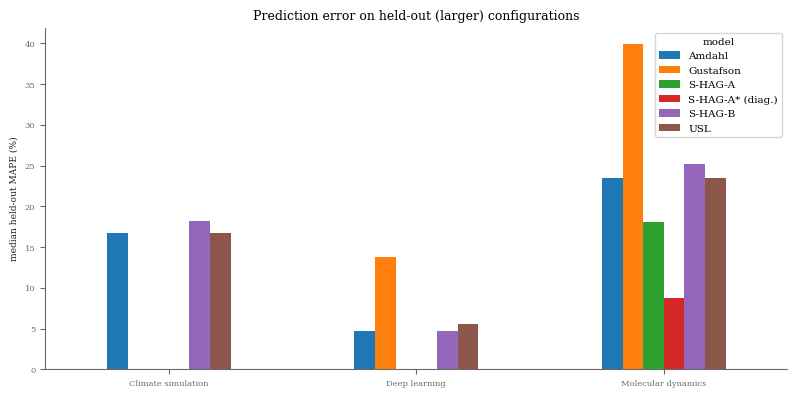

In [ ]:
def make_overview_figures():
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt

    OUT = ROOT / "figures"
    OUT.mkdir(exist_ok=True)
    pred = pd.read_csv(ROOT / "results/predictions.csv")
    acc = pd.read_csv(ROOT / "results/per_series_accuracy.csv")
    dom = pd.read_csv(ROOT / "data/scaling_dataset.csv").groupby("series").domain.first()
    STYLE = {"Amdahl": ("#7a7975", "--"), "Gustafson": ("#7a7975", ":"), "USL": ("#9b59b6", "-."),
             "S-HAG-B": ("#2a78d6", "-"), "S-HAG-A": ("#eb6834", "-"), "S-HAG-A* (diag.)": ("#eb6834", ":")}

    for d in dom.unique():
        series = [s for s in pred.series.unique() if dom[s] == d]
        n = len(series); cols = 4; rows = int(np.ceil(n / cols))
        fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
        for ax, s in zip(axs.flat, series):
            x = pred[pred.series == s]
            obs = x.drop_duplicates("P")
            cal = obs[obs.role == "cal"]; held = obs[obs.role == "held-out"]
            ax.plot(cal.P, cal.S_obs, "ko", ms=4, label="observed (calibration)")
            ax.plot(held.P, held.S_obs, "o", mfc="white", mec="k", ms=5, label="observed (held-out)")
            for m, g in x.groupby("model"):
                c, ls = STYLE.get(m, ("k", "-"))
                ax.plot(g.P, g.S_pred, color=c, ls=ls, lw=1.4, label=m)
            ax.set_xscale("log", base=2); ax.set_title(s, fontsize=8); ax.tick_params(labelsize=7)
            ax.set_xlabel("P", fontsize=7); ax.set_ylabel("speedup", fontsize=7)
        for ax in axs.flat[n:]:
            ax.axis("off")
        h, l = axs.flat[0].get_legend_handles_labels()
        allh = {}
        for ax in axs.flat[:n]:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                allh.setdefault(ll, hh)
        fig.legend(list(allh.values()), list(allh.keys()), loc="lower center", ncol=4, fontsize=8, frameon=False)
        fig.suptitle(f"{d}: observed and predicted speedup", fontsize=11)
        fig.tight_layout(rect=(0, 0.06, 1, 0.97))
        fig.savefig(OUT / f"speedup_{d.replace(' ', '_').lower()}.png", dpi=150)
        plt.close(fig)

    summ = acc.groupby(["domain", "model"]).MAPE.median().unstack()
    ax = summ.plot.bar(figsize=(8, 4), rot=0)
    ax.set_ylabel("median held-out MAPE (%)"); ax.set_xlabel("")
    ax.set_title("Prediction error on held-out (larger) configurations")
    plt.tight_layout(); plt.savefig(OUT / "error_summary.png", dpi=150)
    print("figures written to", OUT)
    print(summ.round(1).to_string())


make_overview_figures()

### 8.2 Paper figures (Figs. 2–4)

```text
Column-width figures for Section VI (IEEE, 3.45 in wide), from results/*.csv.
fig2_lammps.png   observed vs predicted speedup, four LAMMPS series (E1)
fig3_gromacs.png  heterogeneity transfer, CPU-calibrated predictions of GPU-node runs (E2)
fig4_cases.png    case studies where every fitted model misses (MPAS Juqueen, CESM2)
```

In [ ]:
def make_paper_figures():
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt

    OUT = ROOT / "figures"; OUT.mkdir(exist_ok=True)
    pred = pd.read_csv(ROOT / "results/predictions.csv")
    D = pd.read_csv(ROOT / "data/scaling_dataset.csv")
    BLUE, ORANGE, PURPLE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#8a5cc4", "#7a7975", "#1f1f1e", "#6b6a66"
    plt.rcParams.update({"font.family": "serif", "font.size": 7, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                         "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                         "axes.spines.right": False, "xtick.labelsize": 6, "ytick.labelsize": 6,
                         "axes.labelsize": 6.5, "axes.titlesize": 6.5})


    def observed(ax, sid, sd=True):
        x = pred[pred.series == sid].drop_duplicates("P").sort_values("P")
        d = D[D.series == sid].set_index("P")
        err = None
        if sd and d.perf_sd.notna().all():
            b = d.iloc[0]
            rel = np.sqrt((d.perf_sd / d.perf) ** 2 + (b.perf_sd / b.perf) ** 2)
            err = 2 * rel.reindex(x.P).values * x.S_obs.values
        cal, held = x.role == "cal", x.role == "held-out"
        ax.errorbar(x.P[cal], x.S_obs[cal], yerr=None if err is None else err[cal.values], fmt="o", ms=3,
                    color=INK, elinewidth=0.6, capsize=1.2, zorder=5, label="Observed (calibration)")
        ax.errorbar(x.P[held], x.S_obs[held], yerr=None if err is None else err[held.values], fmt="o", ms=3.3,
                    mfc="white", mec=INK, color=INK, elinewidth=0.6, capsize=1.2, zorder=5, label="Observed (held-out)")
        calmax = x.P[cal].max()
        ax.axvspan(x.P.min(), calmax, color="#f1f0ec", zorder=0, lw=0)


    def line(ax, sid, model, color, ls, label, lw=1.3):
        g = pred[(pred.series == sid) & (pred.model == model)].sort_values("P")
        ax.plot(g.P, g.S_pred, color=color, ls=ls, lw=lw, label=label)


    def style(ax, title, xlabel):
        ax.set_xscale("log", base=2); ax.set_title(title, loc="left", pad=2)
        ax.set_xlabel(xlabel, labelpad=1); ax.grid(True, color="#e4e3df", lw=0.4)
        ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{int(v)}"))


    # ---------- Fig. 2: LAMMPS ----------
    fig, axs = plt.subplots(2, 2, figsize=(3.45, 3.25), dpi=300)
    panels = [("LAMMPS-RHODO-strong", "(a) Rhodopsin, strong", "Amdahl"),
              ("LAMMPS-SPCE-strong", "(b) SPC/E water, strong", "Amdahl"),
              ("LAMMPS-EAM-weak", "(c) EAM copper, weak", "Gustafson"),
              ("LAMMPS-SPCE-weak", "(d) SPC/E water, weak", "Gustafson")]
    for ax, (sid, title, cls) in zip(axs.flat, panels):
        observed(ax, sid)
        line(ax, sid, cls, GRAY, "--", "Amdahl (strong) / Gustafson (weak)")
        line(ax, sid, "USL", PURPLE, "-.", "USL")
        line(ax, sid, "S-HAG-A", ORANGE, "-", "S-HAG-A (component calibration)")
        line(ax, sid, "S-HAG-A* (diag.)", BLUE, ":", "S-HAG-A* (measured communication)", lw=1.2)
        style(ax, title, "Cores P")
        ax.set_xticks([1, 4, 16, 64]); ax.axvline(32, color=MUTED, lw=0.5, ls=(0, (1, 2)))
    for ax in axs[:, 0]:
        ax.set_ylabel("Speedup", labelpad=1)
    h, l = axs[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=5.4, handlelength=2.6, columnspacing=0.8)
    fig.subplots_adjust(left=0.1, right=0.98, top=0.95, bottom=0.25, wspace=0.28, hspace=0.42)
    fig.savefig(OUT / "fig2_lammps.png", dpi=300); plt.close(fig)

    # ---------- Fig. 3: GROMACS heterogeneity transfer ----------
    h = pd.read_csv(ROOT / "results/heterogeneity_gromacs.csv")
    fig, axs = plt.subplots(1, 2, figsize=(3.45, 1.75), dpi=300)
    for ax, sysn, title in zip(axs, ["MEM", "RIB"], ["(a) MEM, 81,743 atoms", "(b) RIB, 2,136,412 atoms"]):
        g = h[h.system == sysn].sort_values("nodes")
        cpu = D[D.series == f"GROMACS-{sysn}-cpu"].sort_values("P")
        ax.plot(cpu.P, cpu.S_obs, "s", ms=2.4, color=GRAY, mfc="white", label="Observed, CPU-only nodes")
        ax.plot(g.nodes, g.S_obs, "o", ms=3.2, color=INK, label="Observed, GPU nodes (held-out)")
        ax.plot(g.nodes, g.Amdahl_x_chi, color=GRAY, ls="--", lw=1.2, label="Amdahl × one-node GPU speedup")
        ax.plot(g.nodes, g.S_HAG, color=ORANGE, lw=1.3, label="S-HAG (CPU calibration + χ)")
        style(ax, title, "Nodes")
        ax.set_xticks([1, 4, 16, 64, 256] if sysn == "RIB" else [1, 4, 16, 64])
    axs[0].set_ylabel("Speedup vs. one CPU node", labelpad=1)
    hh, ll = axs[0].get_legend_handles_labels()
    fig.legend(hh, ll, loc="lower center", ncol=2, frameon=False, fontsize=5.4, handlelength=2.4, columnspacing=0.8)
    fig.subplots_adjust(left=0.11, right=0.98, top=0.9, bottom=0.36, wspace=0.3)
    fig.savefig(OUT / "fig3_gromacs.png", dpi=300); plt.close(fig)

    # ---------- Fig. 4: case studies ----------
    fig, axs = plt.subplots(1, 2, figsize=(3.45, 2.05), dpi=300)
    for ax, sid, title, xl in zip(axs, ["MPAS-120km-Juqueen", "CESM-CESM2.1-f09_g16"],
                                  ["(a) MPAS-A 120 km, Juqueen", "(b) CESM2 1°, Snellius"], ["Nodes", "Cores"]):
        observed(ax, sid, sd=False)
        line(ax, sid, "S-HAG-B", BLUE, "-", "S-HAG-B (end-to-end calibration)", lw=2.2)
        line(ax, sid, "Amdahl", GRAY, "--", "Amdahl", lw=1.1)
        line(ax, sid, "USL", PURPLE, "-.", "USL", lw=1.1)
        ax.set_title(title, loc="left", pad=2); ax.set_xlabel(xl, labelpad=1)
        ax.grid(True, color="#e4e3df", lw=0.4)
        x = np.sort(pred[pred.series == sid].P.unique())
        ax.set_xticks(x); ax.set_xticklabels([f"{int(v)}" for v in x], fontsize=5, rotation=45 if x.max() > 1000 else 0)
    axs[0].set_ylabel("Speedup", labelpad=1)
    hh, ll = axs[0].get_legend_handles_labels()
    fig.legend(hh, ll, loc="lower center", ncol=2, frameon=False, fontsize=5.4, handlelength=2.4, columnspacing=0.8)
    fig.subplots_adjust(left=0.11, right=0.98, top=0.91, bottom=0.42, wspace=0.3)
    fig.savefig(OUT / "fig4_cases.png", dpi=300); plt.close(fig)
    print("written:", [p.name for p in OUT.glob("fig*.png")])


make_paper_figures()

written: ['fig4_cases.png', 'fig1_shag.png', 'fig2_lammps.png', 'fig3_gromacs.png']


error_summary.png


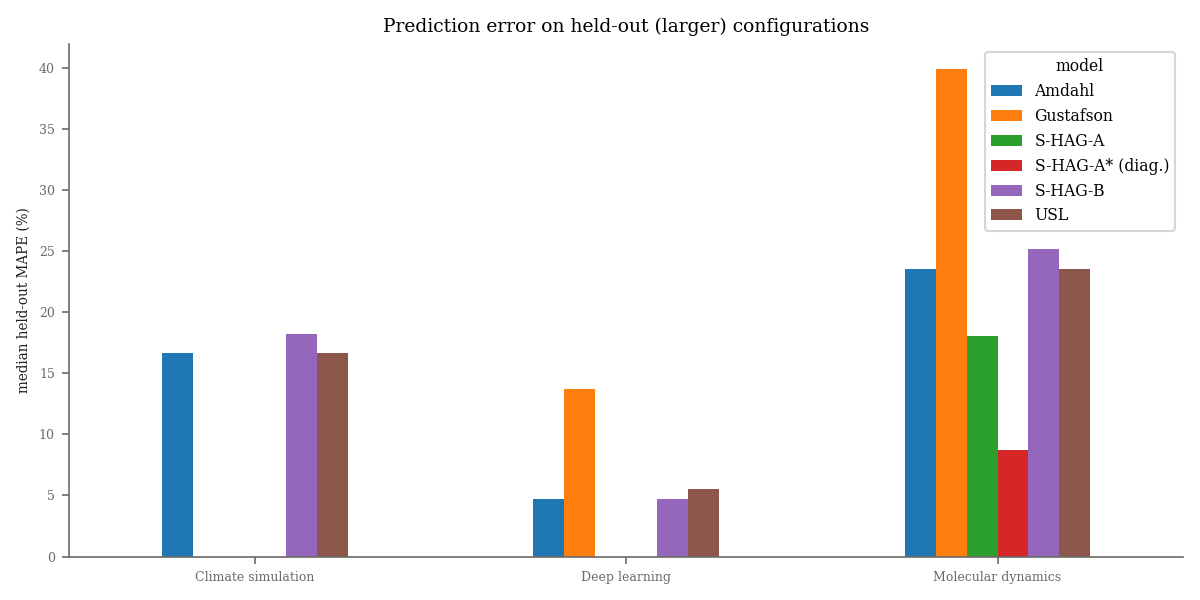

fig1_shag.png


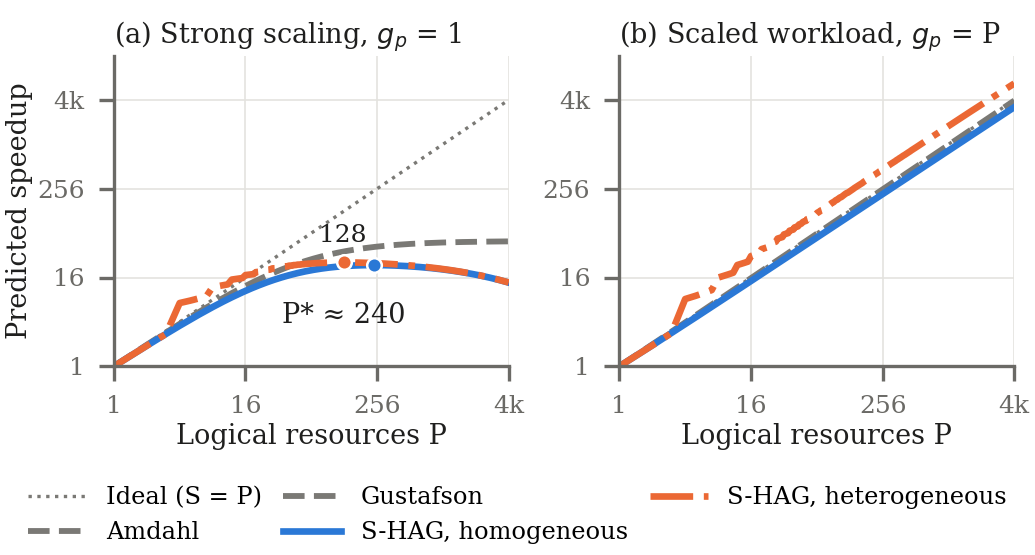

fig2_lammps.png


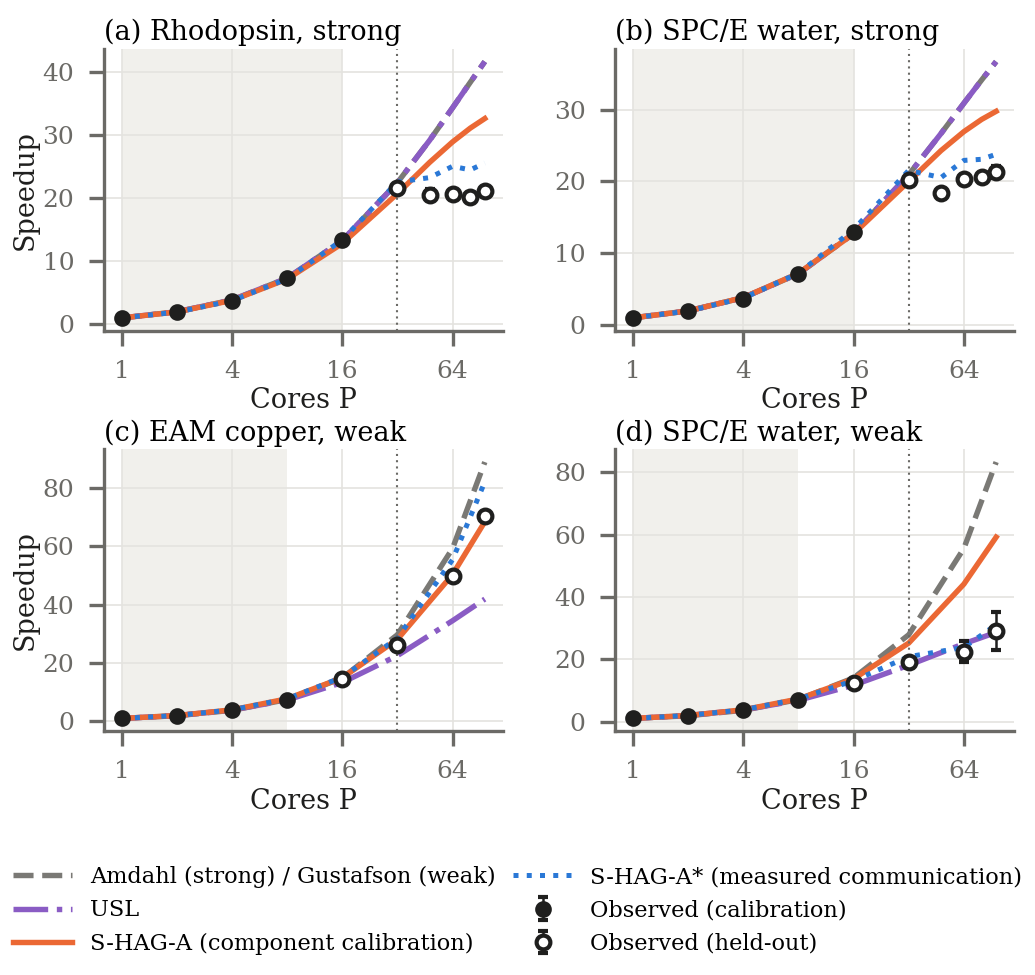

fig3_gromacs.png


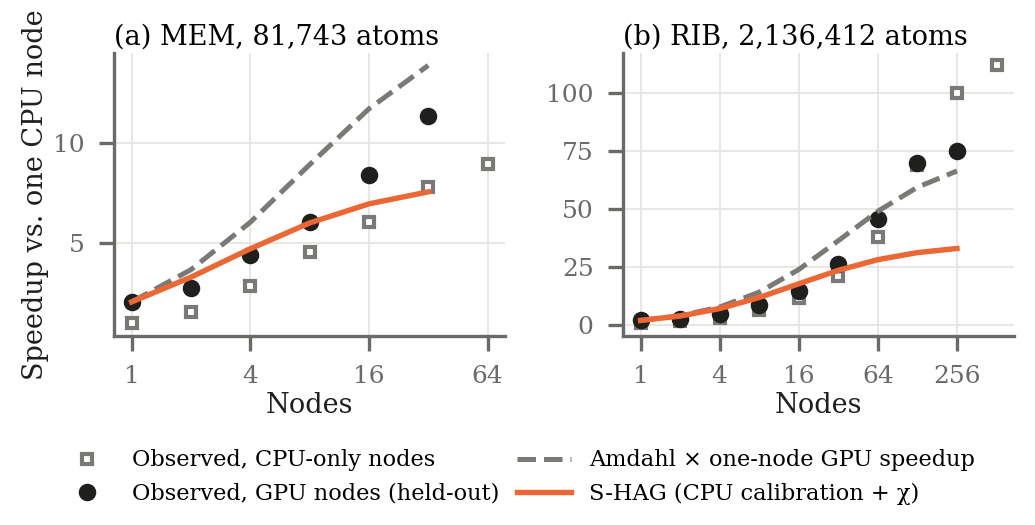

fig4_cases.png


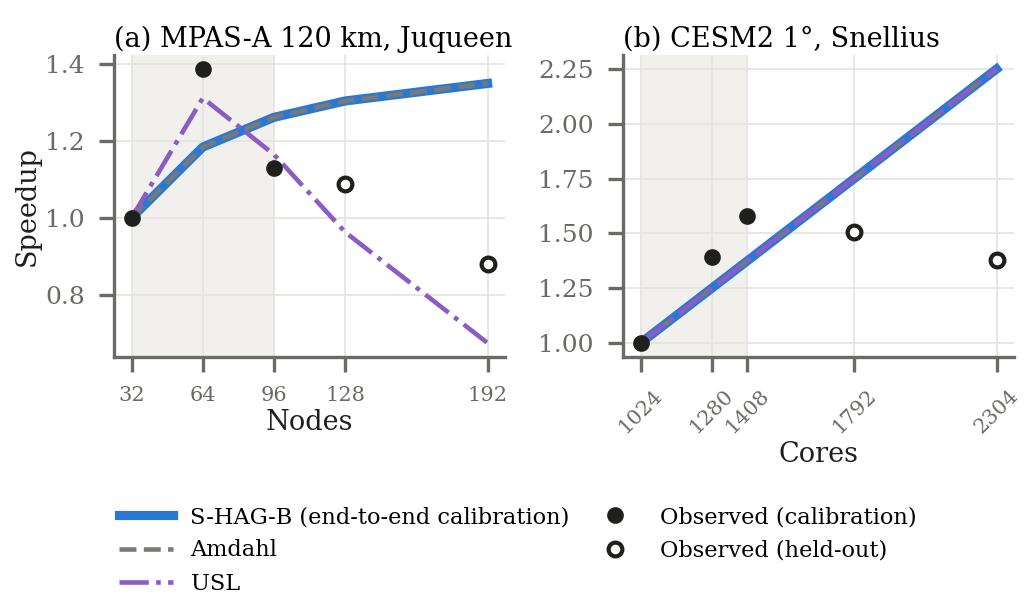

speedup_climate_simulation.png


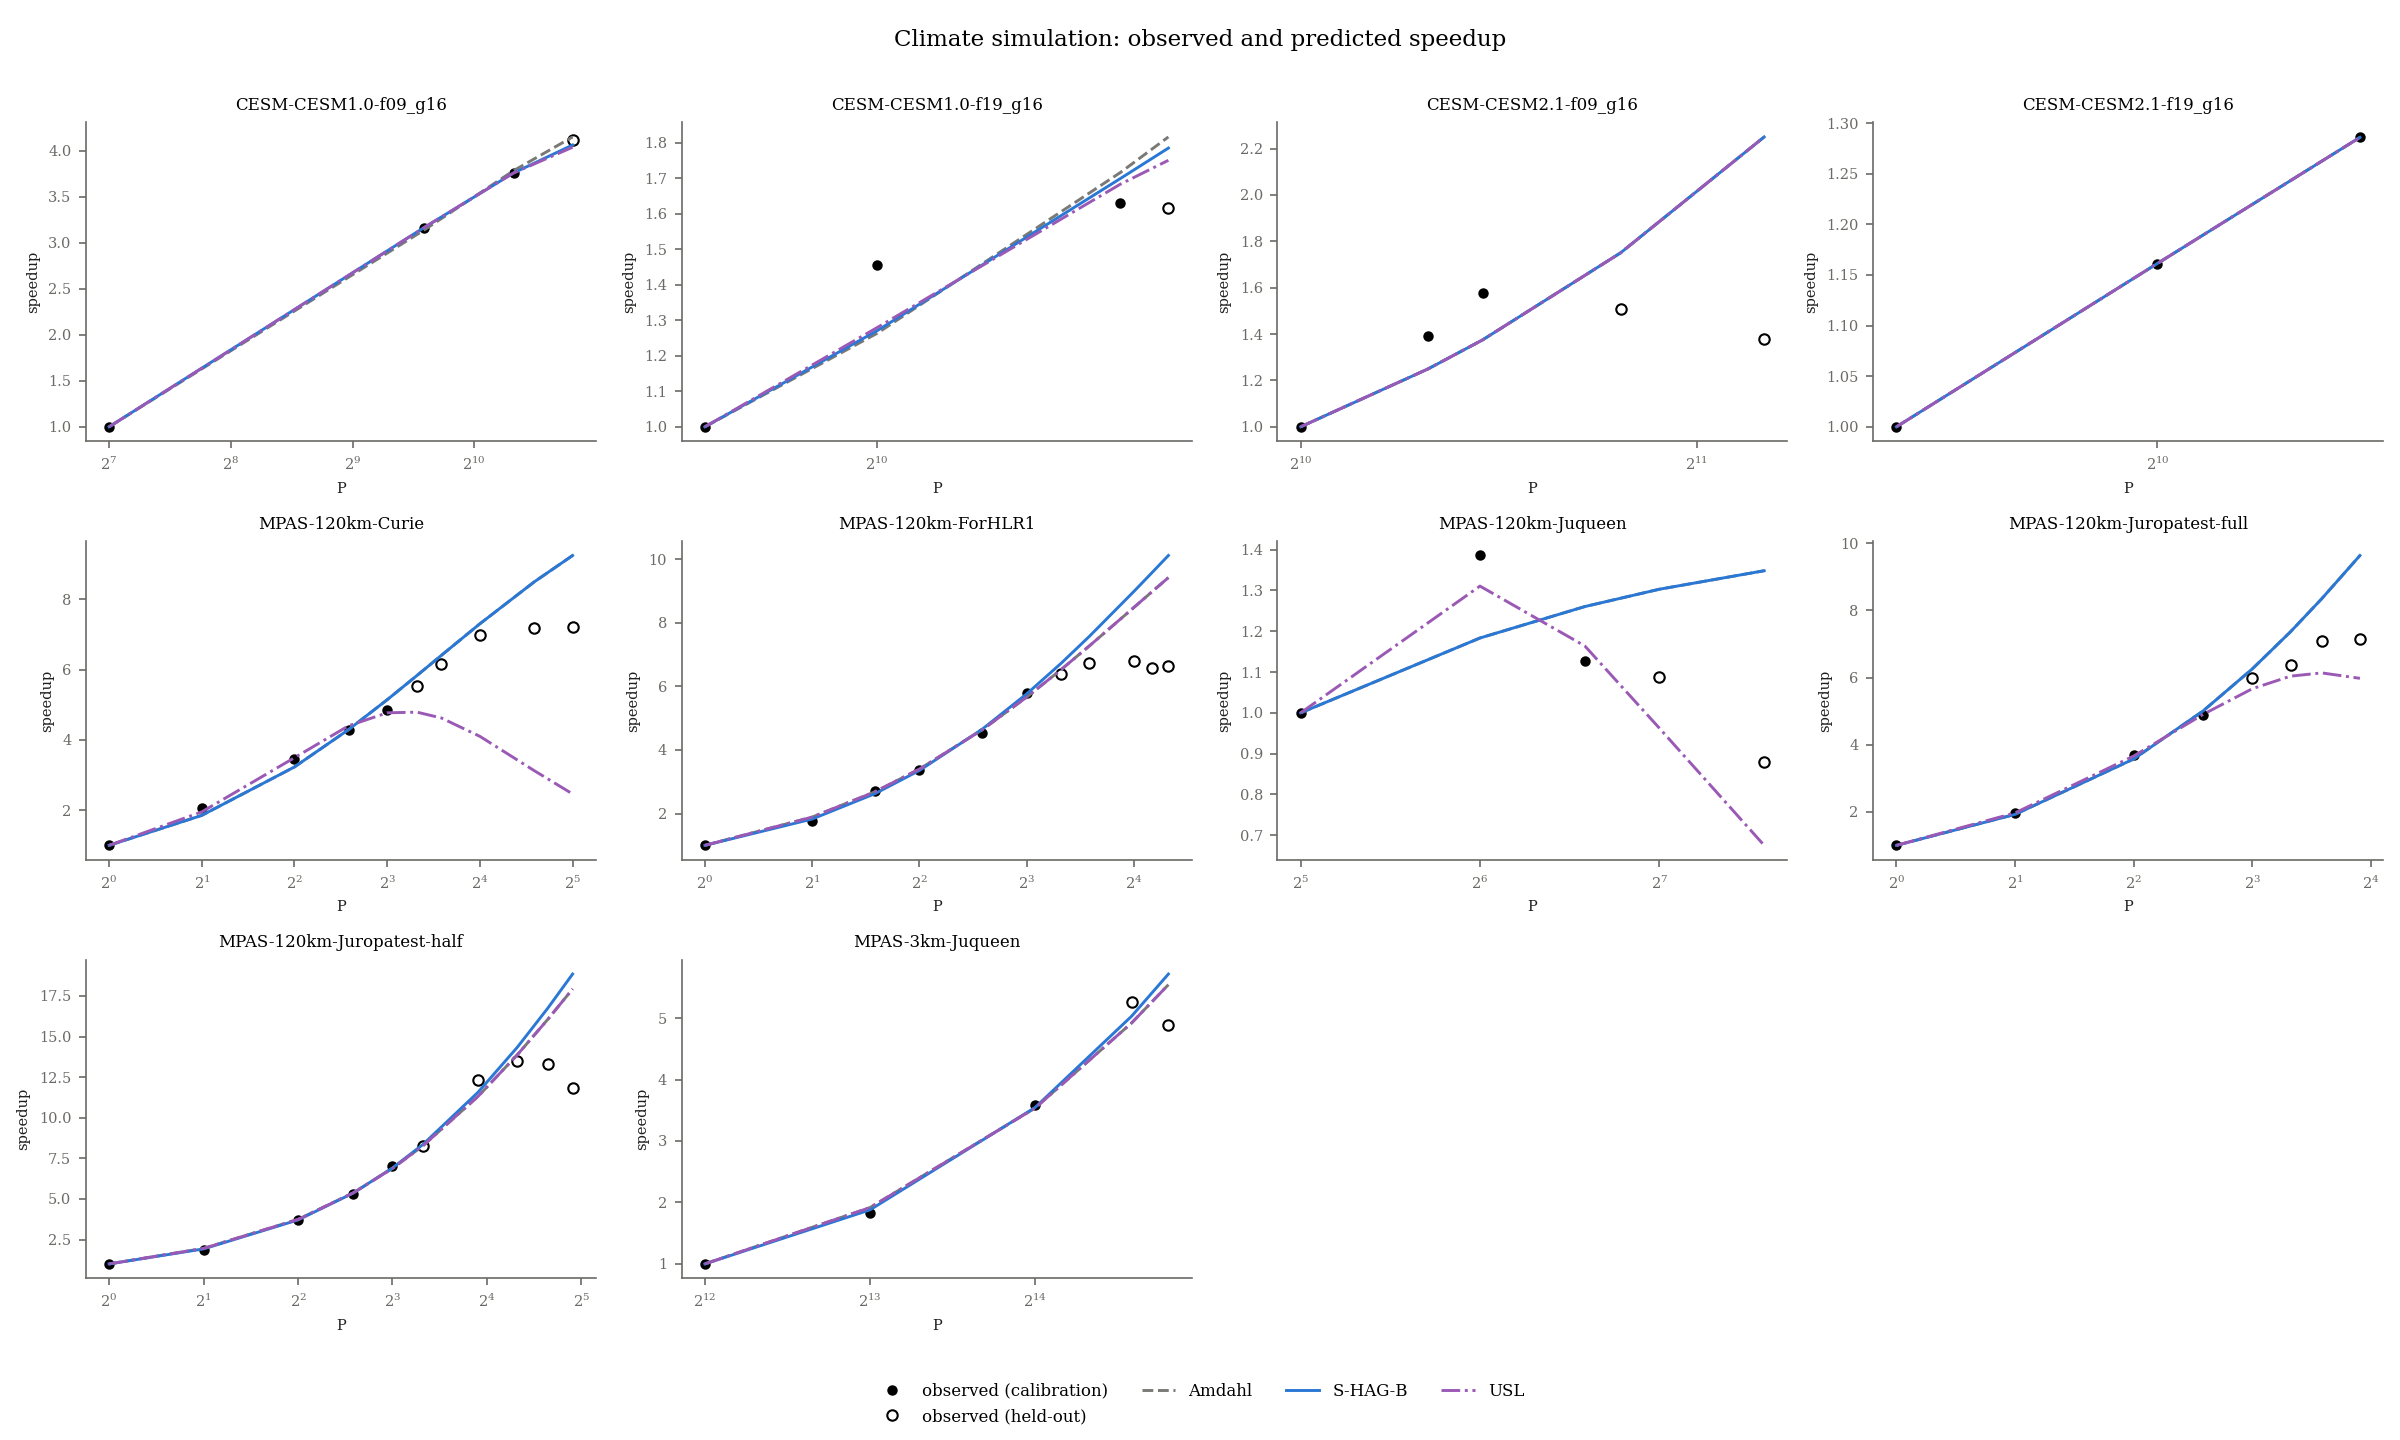

speedup_deep_learning.png


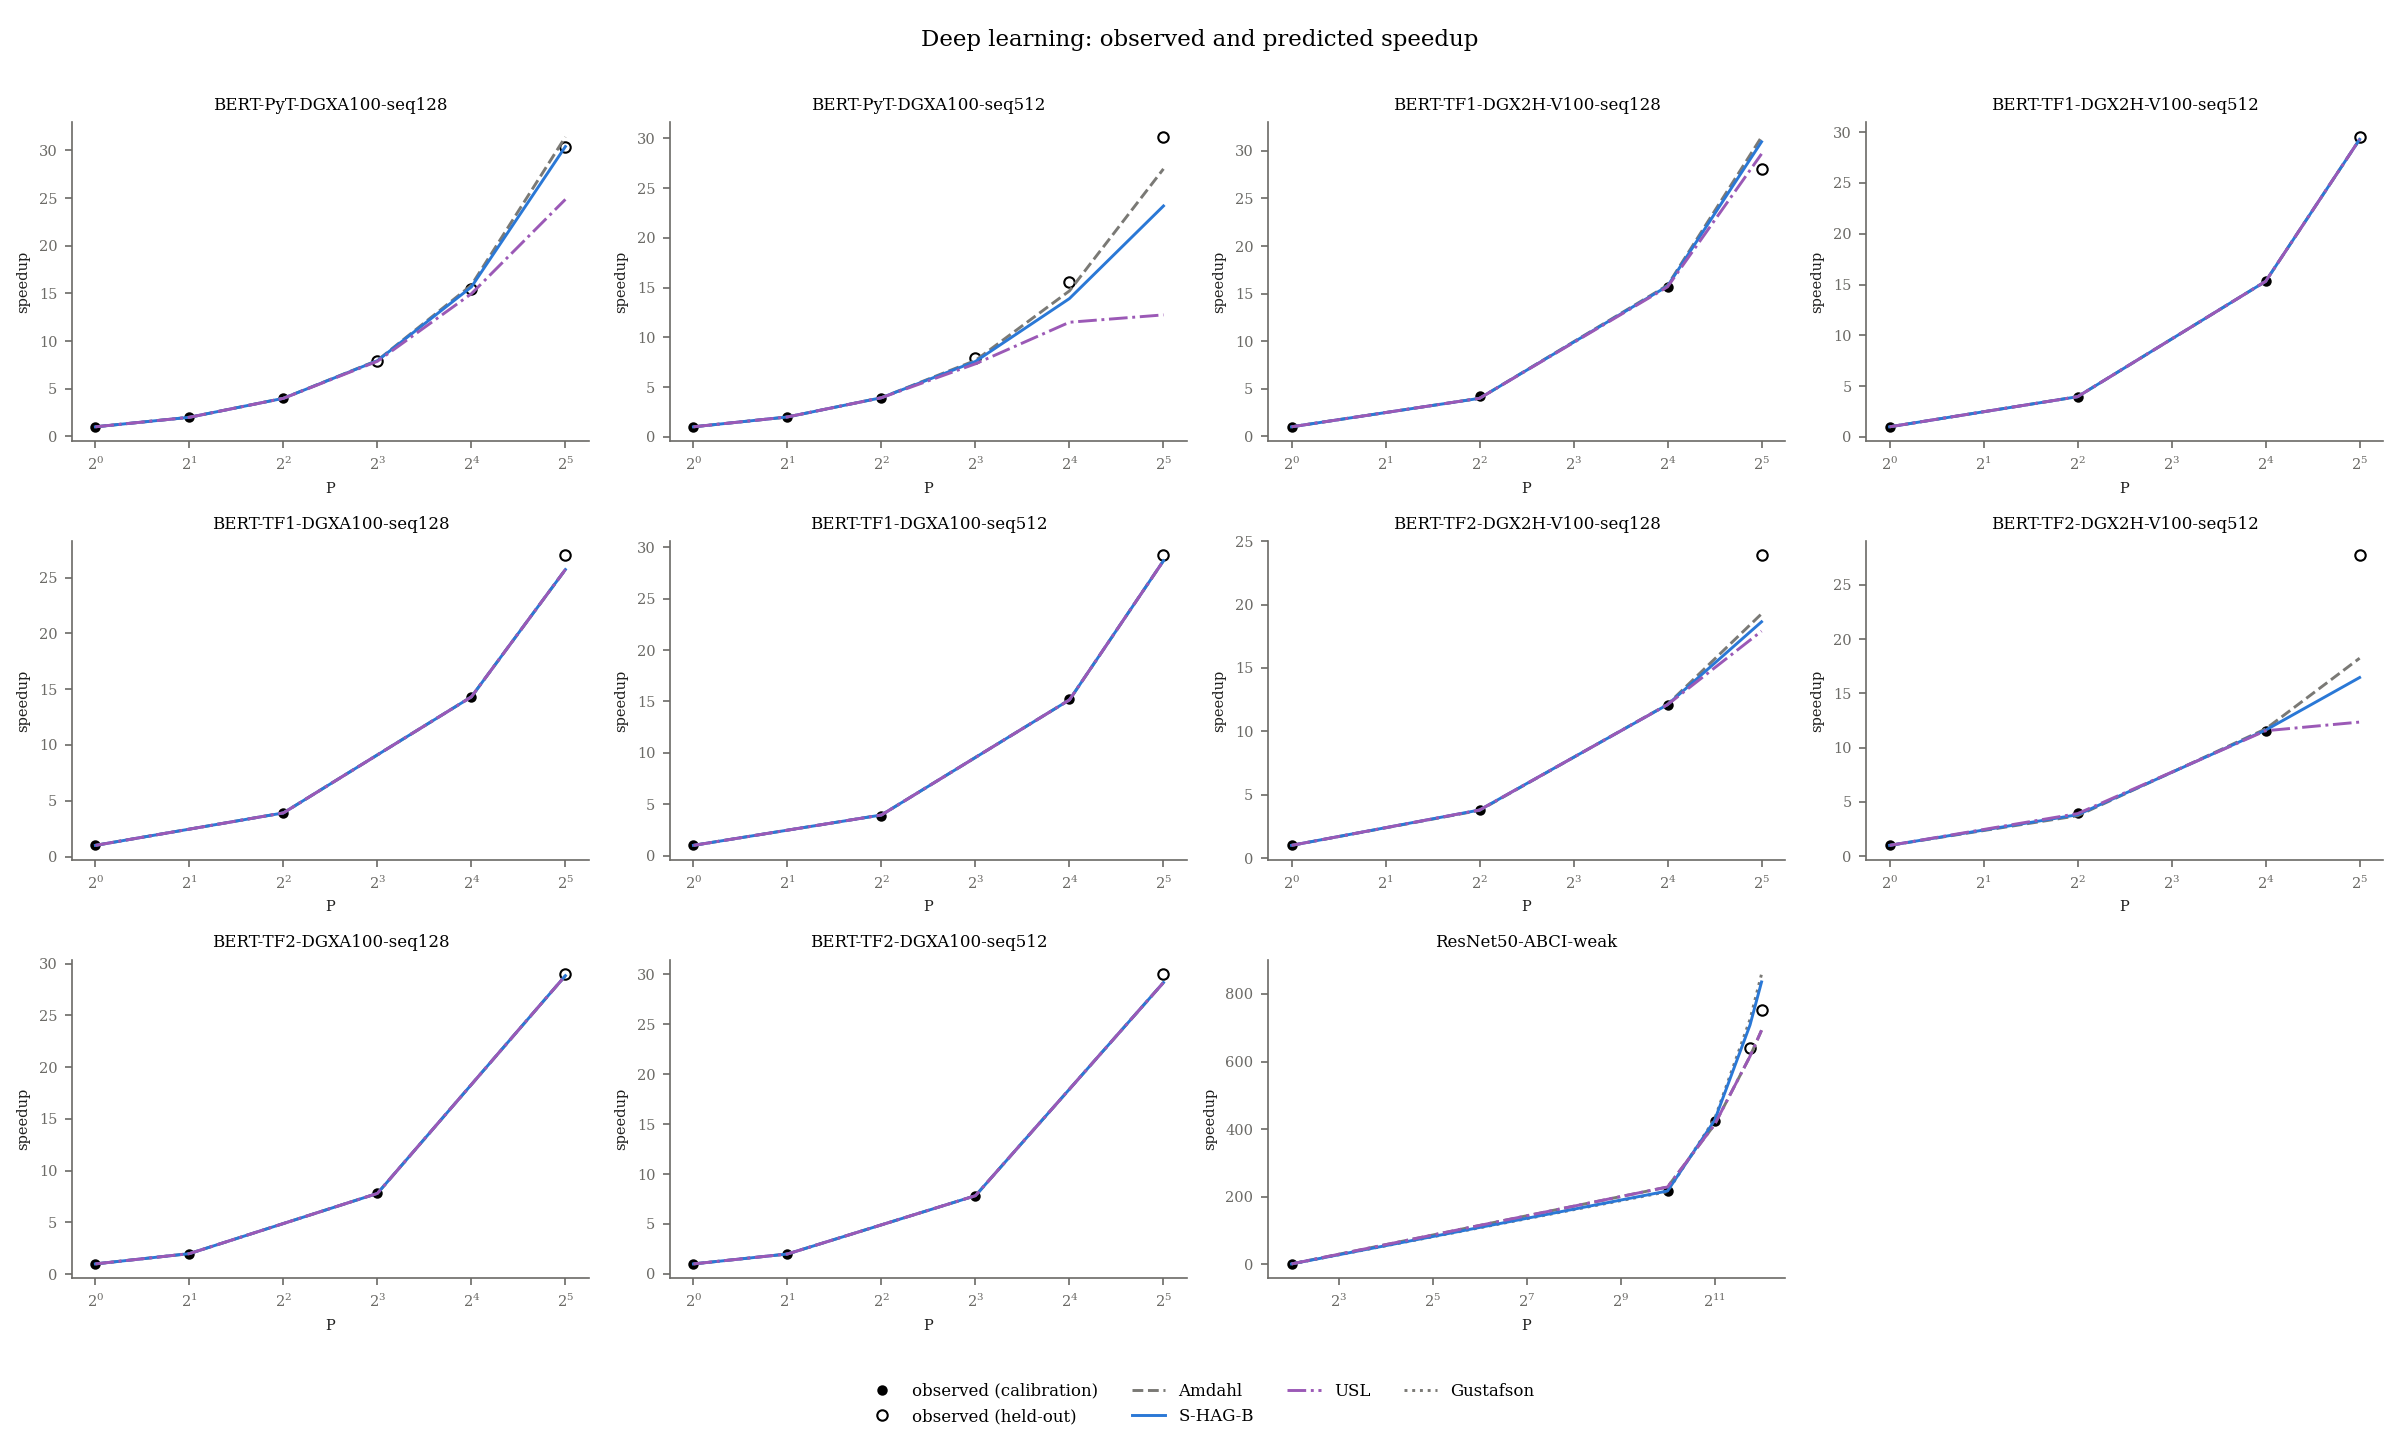

speedup_molecular_dynamics.png


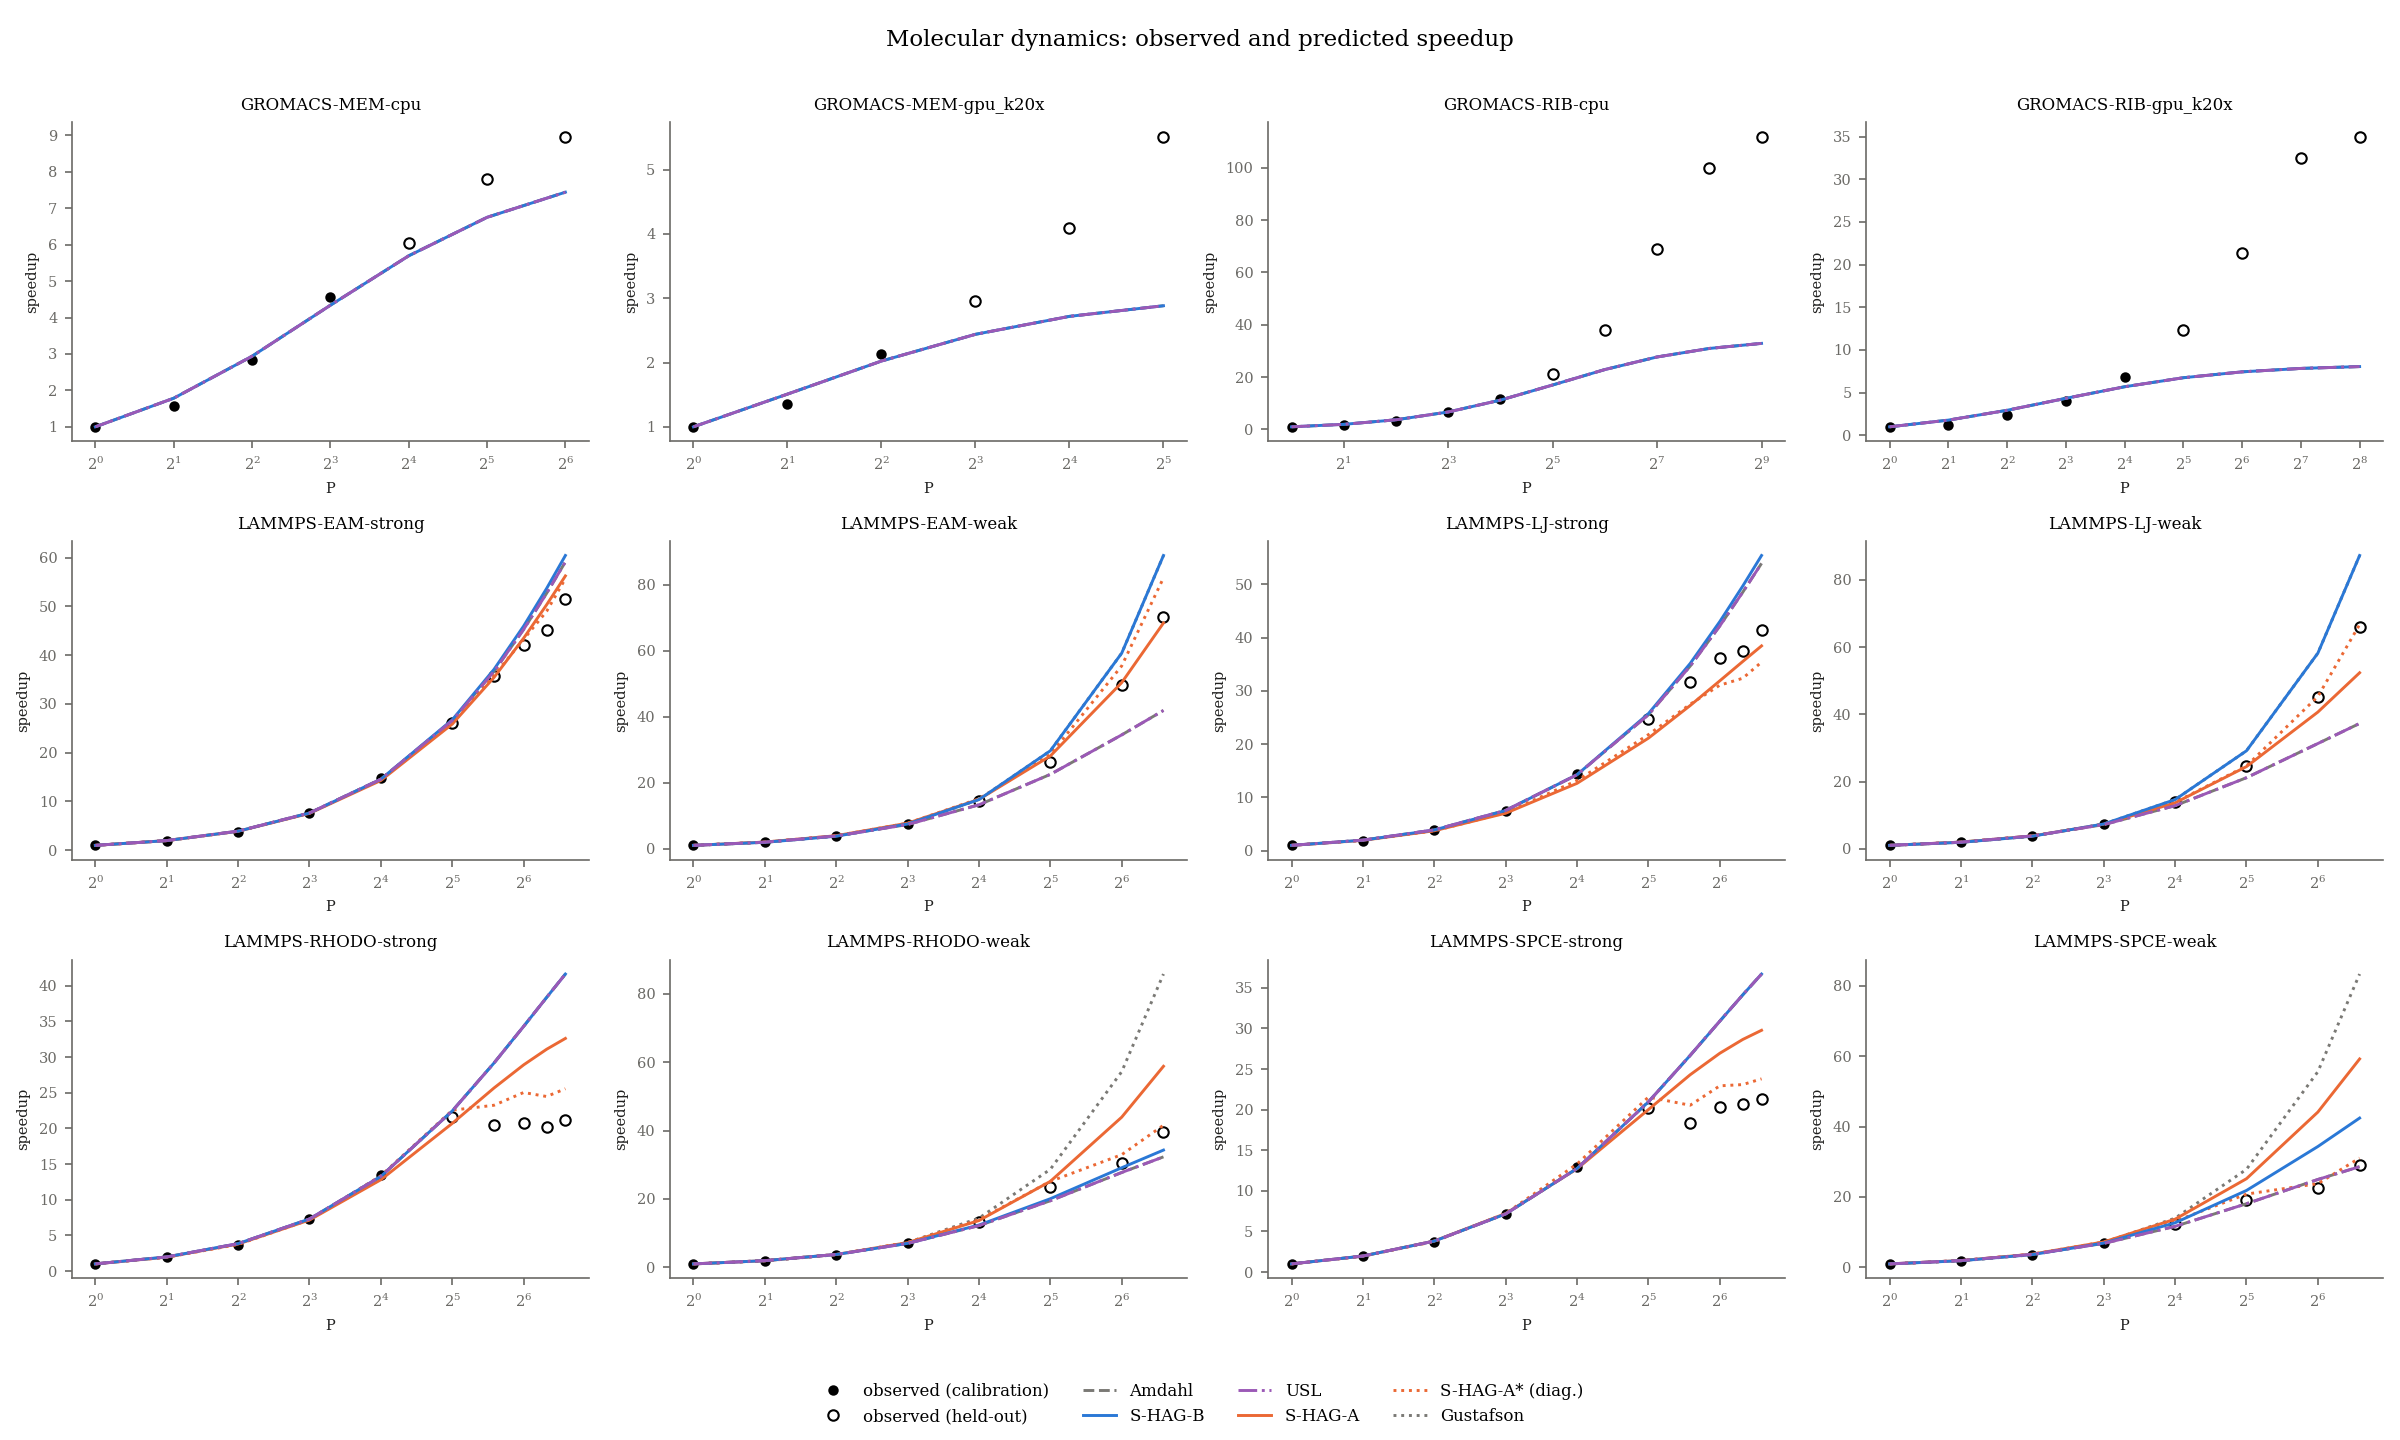

In [ ]:
for f in sorted((ROOT / "figures").glob("*.png")):
    print(f.name); display(Image(filename=str(f), width=900 if "speedup_" in f.name else 520))

## 9. Summary tables

In [ ]:
acc = pd.read_csv(ROOT / "results/per_series_accuracy.csv")
print("Median held-out MAPE (%) by domain and model (Table V)")
display(acc.groupby(["domain", "model"]).MAPE.median().unstack().round(1))
print("Held-out MAPE (%) per series")
display(acc.pivot_table(index=["domain", "series"], columns="model", values="MAPE").round(1))
het = pd.read_csv(ROOT / "results/heterogeneity_gromacs.csv")
ape = lambda c: (abs(het[c] - het.S_obs) / het.S_obs * 100)
print("Heterogeneity transfer, MAPE (%) (Table VIII)")
display(het.assign(**{f"APE {c}": ape(c) for c in ["S_HAG", "Amdahl_x_chi", "USL_x_chi"]})
        .groupby("system")[[f"APE {c}" for c in ["S_HAG", "Amdahl_x_chi", "USL_x_chi"]]].mean().round(1))
w = pd.read_csv(ROOT / "results/amdahl_weak_underestimation.csv")
print("Amdahl vs. observed scaled speedup at 96 cores (Table VII)")
display(w[w.P == 96][["benchmark", "s_amdahl", "S_scaled_obs", "Amdahl_fixed_size", "ratio_obs_over_amdahl"]].round(3))
print("Refinement tests (Table IX)")
display(pd.read_csv(ROOT / "results/improvements_test.csv").round(1))
display(pd.read_csv(ROOT / "results/improvement1_node_test.csv").round(1))

Median held-out MAPE (%) by domain and model (Table V)


model,Amdahl,Gustafson,S-HAG-A,S-HAG-A* (diag.),S-HAG-B,USL
domain,,,,,,
Climate simulation,16.7,NaN,NaN,NaN,18.2,16.7
Deep learning,4.7,13.7,NaN,NaN,4.7,5.5
Molecular dynamics,23.5,39.9,18.0,8.7,25.2,23.5


Held-out MAPE (%) per series


model                                          Amdahl  Gustafson  S-HAG-A  S-HAG-A* (diag.)  S-HAG-B   USL
domain             series                                                                                 
Climate simulation CESM-CESM1.0-f09_g16           0.8        NaN      NaN               NaN      1.4   2.0
                   CESM-CESM1.0-f19_g16          12.3        NaN      NaN               NaN     10.4   8.2
                   CESM-CESM2.1-f09_g16          39.7        NaN      NaN               NaN     39.7  39.7
                   MPAS-120km-Curie              12.1        NaN      NaN               NaN     12.1  40.4
                   MPAS-120km-ForHLR1            22.6        NaN      NaN               NaN     29.5  22.6
                   MPAS-120km-Juqueen            36.5        NaN      NaN               NaN     36.5  17.4
                   MPAS-120km-Juropatest-full    18.2        NaN      NaN               NaN     18.2  10.0
                   MPAS-120km-Juropatest-half    16.7        NaN      NaN               NaN     19.8  16.7
                   MPAS-3km-Juqueen               9.8        NaN      NaN               NaN     10.6   9.8
Deep learning      BERT-PyT-DGXA100-seq128        2.4        NaN      NaN               NaN      0.7   7.3
                   BERT-PyT-DGXA100-seq512        6.3        NaN      NaN               NaN     12.5  30.7
                   BERT-TF1-DGX2H-V100-seq128    11.9        NaN      NaN               NaN     10.1   5.5
                   BERT-TF1-DGX2H-V100-seq512     0.8        NaN      NaN               NaN      0.8   0.8
                   BERT-TF1-DGXA100-seq128        4.7        NaN      NaN               NaN      4.7   4.7
                   BERT-TF1-DGXA100-seq512        1.7        NaN      NaN               NaN      1.7   1.7
                   BERT-TF2-DGX2H-V100-seq128    19.3        NaN      NaN               NaN     21.9  25.0
                   BERT-TF2-DGX2H-V100-seq512    34.2        NaN      NaN               NaN     40.6  55.4
                   BERT-TF2-DGXA100-seq128        0.5        NaN      NaN               NaN      0.5   0.5
                   BERT-TF2-DGXA100-seq512        2.8        NaN      NaN               NaN      2.8   2.8
                   ResNet50-ABCI-weak             5.9       13.7      NaN               NaN     10.9   5.9
Molecular dynamics GROMACS-MEM-cpu               12.1        NaN      NaN               NaN     12.1  12.1
                   GROMACS-MEM-gpu_k20x          32.9        NaN      NaN               NaN     32.9  32.9
                   GROMACS-RIB-cpu               51.8        NaN      NaN               NaN     51.8  51.8
                   GROMACS-RIB-gpu_k20x          65.8        NaN      NaN               NaN     65.8  65.8
                   LAMMPS-EAM-strong              8.7        NaN      5.2               4.1     10.4   8.7
                   LAMMPS-EAM-weak               23.2       15.5      3.7              10.5     15.5  23.2
                   LAMMPS-LJ-strong              17.7        NaN     10.6              13.5     20.0  17.7
                   LAMMPS-LJ-weak                23.8       21.4      8.0               0.4     21.4  23.8
                   LAMMPS-RHODO-strong           59.8        NaN     35.6              16.1     59.8  59.8
                   LAMMPS-RHODO-weak             13.3       58.4     25.4               6.0     10.0  13.3
                   LAMMPS-SPCE-strong            47.6        NaN     28.8              10.9     47.6  47.6
                   LAMMPS-SPCE-weak               6.0       98.3     60.7               7.0     28.9   6.0

Heterogeneity transfer, MAPE (%) (Table VIII)


,APE S_HAG,APE Amdahl_x_chi,APE USL_x_chi
system,,,
MEM,12.9,29.7,29.7
RIB,34.5,34.2,34.2


Amdahl vs. observed scaled speedup at 96 cores (Table VII)


,benchmark,s_amdahl,S_scaled_obs,Amdahl_fixed_size,ratio_obs_over_amdahl
7,LJ,0.008,66.130,53.907,1.227
15,EAM,0.007,70.204,59.128,1.187
23,RHODO,0.014,39.537,41.631,0.950
31,SPCE,0.017,29.074,36.696,0.792


Refinement tests (Table IX)


,improvement,series,current,improved,improved_3par,Amdahl,USL,n_cal,n_held
0,2 halo (S-HAG-A),LAMMPS-LJ-strong,10.6,9.7,NaN,NaN,NaN,NaN,NaN
1,2 halo (S-HAG-A),LAMMPS-EAM-strong,5.2,5.4,NaN,NaN,NaN,NaN,NaN
2,2 halo (S-HAG-A),LAMMPS-RHODO-strong,35.6,35.6,NaN,NaN,NaN,NaN,NaN
3,2 halo (S-HAG-A),LAMMPS-SPCE-strong,28.8,28.8,NaN,NaN,NaN,NaN,NaN
4,3 FFT work growth (S-HAG-A),LAMMPS-RHODO-weak,25.4,25.4,NaN,NaN,NaN,NaN,NaN
5,3 FFT work growth (S-HAG-A),LAMMPS-SPCE-weak,60.7,60.7,NaN,NaN,NaN,NaN,NaN
6,2 halo (S-HAG-B),MPAS-120km-Curie,12.1,12.1,12.1,12.1,40.4,5.0,5.0
7,2 halo (S-HAG-B),MPAS-120km-ForHLR1,29.5,30.6,29.5,22.6,22.6,6.0,5.0
8,2 halo (S-HAG-B),MPAS-120km-Juqueen,36.5,36.5,36.5,36.5,17.4,3.0,2.0
9,2 halo (S-HAG-B),MPAS-120km-Juropatest-full,18.2,18.2,18.2,18.2,10.0,4.0,4.0


,series,S-HAG-A current,S-HAG-A node-aware,classical,classical_model,USL
0,LAMMPS-LJ-strong,7.3,7.3,14.8,Amdahl,2.4
1,LAMMPS-EAM-strong,8.2,8.2,9.4,Amdahl,6.7
2,LAMMPS-RHODO-strong,39.1,7.0,43.0,Amdahl,8.6
3,LAMMPS-SPCE-strong,12.2,19.7,26.6,Amdahl,19.6
4,LAMMPS-LJ-weak,14.3,14.3,22.0,Gustafson,20.9
5,LAMMPS-EAM-weak,2.8,2.8,17.5,Gustafson,16.8
6,LAMMPS-RHODO-weak,44.7,44.7,86.5,Gustafson,13.0
7,LAMMPS-SPCE-weak,33.2,33.2,130.4,Gustafson,14.4


## 10. Download every output as one zip

In [ ]:
out = ROOT / "SHAG_outputs.zip"
items = (sorted((ROOT / "results").glob("*")) + sorted((ROOT / "figures").glob("*.png")) +
         [ROOT / "data/scaling_dataset.csv", ROOT / "data/consistency_checks.csv"])
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for p in items:
        if p.exists():
            z.write(p, p.relative_to(ROOT).as_posix())
    z.writestr("README.txt", f"S-HAG outputs, generated {datetime.datetime.now():%Y-%m-%d %H:%M}\n")
print(f"{out}  ({out.stat().st_size/1024:.0f} KB, {len(items)} files)")
try:
    from google.colab import files
    files.download(str(out))
except ImportError:
    print("Not in Colab: the zip is saved at the path above.")

/content/shag_work/SHAG_outputs.zip  (1130 KB, 19 files)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Appendix A. Cluster measurement kit (Section V-D, item 6)
These cells only **write the files** to `shag_work/kit/`; they are not run in Colab. Copy the folder to a Slurm cluster
and follow `kit/README.md`. `analyze_own_runs.py` imports the model from `shag_work/model/shag.py` (Part 2).

In [ ]:
for d in ['climate', 'common', 'dl', 'md', 'md/inputs', 'microbench', 'parsers']:
    (ROOT / 'kit' / d).mkdir(parents=True, exist_ok=True)
print('kit folders ready')

kit folders ready


In [ ]:
%%writefile shag_work/kit/README.md
# S-HAG cluster experiment kit

Runs the controlled measurement protocol of Section V-D on a Slurm cluster, then produces
component-calibrated S-HAG predictions next to Amdahl, Gustafson and USL.

## What it measures

| Application | Script | Scaling | Component timers used by S-HAG |
|---|---|---|---|
| LAMMPS (LJ, 32k atoms/rank weak, 256k atoms strong) | `md/lammps_scaling.sbatch` | strong + weak | Pair/Neigh/Modify (parallel), Comm, Kspace, Output+Other (serial), Pair max−avg (imbalance) |
| GROMACS benchMEM / benchRIB | `md/gromacs_scaling.sbatch` | strong, CPU-only and GPU nodes | cycle-accounting table: Comm./Wait/PME-redist (comm), Update/Constraints/Write (serial) |
| ResNet-50, BERT-large-like encoder | `dl/ddp_bench.sbatch` → `dl/ddp_bench.py` | weak (ResNet), strong (BERT) | compute (no_sync), optimizer (serial), gradient all-reduce, max−mean over ranks |
| MPAS-A 120 km | `climate/mpas_scaling.sbatch` | strong | built-in timer table (halo exchange, I/O, integration) |
| CESM B1850 | `climate/CESM_PE_SWEEP.md` | strong, PE-layout sweep | CIME timing file: component run times, CPL COMM time |
| Network + noise | `microbench/microbench.sbatch` (OSU + `fwq.c`) | all target P | all-reduce / all-to-all / barrier latency, FWQ noise σₐ |

## Run order

1. Build `microbench/fwq` (`mpicc -O1 -o microbench/fwq microbench/fwq.c -lm`) and the OSU Micro-Benchmarks with
   the same MPI as the applications.
2. For every node count N in {1, 2, 4, 8, 16, …}: `sbatch --nodes=N <script>` for each application and for
   `microbench.sbatch`. Use exclusive nodes, the same software stack and the same pinning for all runs.
   At least 5 repetitions for CPU codes, 3 for DL and climate.
3. `python collect.py results --allreduce-bytes <gradient bytes> --alltoall-bytes <FFT block bytes>`
   → `components.csv`, `microbench.csv`.
4. `python analyze_own_runs.py components.csv [microbench_mapped.csv]`
   → `results/own_predictions.csv`, `results/own_accuracy.csv`.

The P = 1 run of every series is the reference resource of Section IV (one core, one GPU, or one node,
stated explicitly). Calibration uses the smallest ⌈n/2⌉ resource counts; the larger ones are held out.

## What was tested here (2 CPU cores, no GPU, no scheduler)

| Component | Test |
|---|---|
| `microbench/fwq.c` | compiled with MPICH and run on 2 ranks |
| `dl/ddp_bench.py` | run with torchrun on CPU/gloo, 1 and 2 processes, ResNet-18 and a small Transformer |
| `parsers.parse_lammps` | on a real LAMMPS log (LJ, 32,000 atoms) |
| `parsers.parse_ddp`, `parse_fwq` | on the real outputs above |
| `analyze_own_runs.py` | on the real FABRIC LAMMPS timers (216 runs); reproduces the component-calibrated results of the main pipeline |
| `collect.py` | on a results tree containing the real outputs above |
| `*.sbatch` | `bash -n` syntax check only |
| `parse_gromacs`, `parse_mpas`, `parse_cesm`, `parse_osu` | **not run on real output**: check the first parsed file by hand |

Nothing in this kit has been run on a multi-node cluster or a GPU.

Writing shag_work/kit/README.md


In [ ]:
%%writefile shag_work/kit/analyze_own_runs.py
"""Component-calibrated S-HAG prediction for your own runs (Section V-D, protocol for new measurements).

Input : components.csv produced by collect.py (schema in parsers/parsers.py), optionally
        microbench.csv (P, t_comm_micro) from collect.py --microbench.
Output: results/own_predictions.csv, results/own_accuracy.csv

Per series:
  calibration P  = the ceil(n/2) smallest resource counts (>= 3); held-out = the rest
  T_ser          = t_serial at the smallest P (g_s = 1)
  T_par          = t_parallel at the smallest P, scaled by P0/P (strong) or constant (weak)
  c_v            = mean over calibration P of t_imbalance / (t_parallel * m(P))
  comm(P)        = nonnegative fit c0 + lam log2 P + beta (P-1) to t_comm at calibration P,
                   or to the micro-benchmark times at ALL target P when microbench.csv is given
                   (Section IV-E step 4: micro-benchmarks are cheap at full scale)
  kspace(P)      = (LAMMPS PPPM only) a/P + b log2 P + c (P-1) fitted at calibration P
  T(P)           = T_ser + T_par(P) [1 + c_v m(P)] + kspace(P) + comm(P)            -> eq. (7)
Classical baselines (Amdahl, Gustafson for weak, USL) are fitted to end-to-end speedups at the
same calibration P.  Usage:  python analyze_own_runs.py components.csv [microbench.csv]
"""
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import least_squares, nnls

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "model"))
import shag as M  # noqa: E402


def fitnn(P, y, cols):
    X = np.c_[[c(P) for c in cols]].T
    coef, _ = nnls(X, y)
    return coef


def run(comp_csv, micro_csv=None, out_dir="results"):
    C = pd.read_csv(comp_csv)
    micro = pd.read_csv(micro_csv) if micro_csv else None
    Path(out_dir).mkdir(exist_ok=True)
    preds, acc = [], []
    for sid, s in C.groupby("series"):
        g = s.groupby("P").mean(numeric_only=True).sort_index()
        sd = s.groupby("P").t_total.std()
        P = g.index.values.astype(float)
        n = len(P)
        nc = max(3, int(np.ceil(n / 2)))
        if n <= nc:
            print(f"{sid}: {n} resource counts -> no held-out point, skipped"); continue
        weak = s["mode"].iloc[0] == "weak"
        P0 = P[0]
        p = P / P0
        T = g.t_total.values
        S_obs = (p * T[0] / T) if weak else (T[0] / T)
        cal = slice(0, nc)
        ser, par0 = g.t_serial.values[0], g.t_parallel.values[0]
        par = par0 * (np.ones_like(P) if weak else P0 / P)
        mP = M.m_max(p)
        ok = (mP[cal] > 0) & (g.t_parallel.values[cal] > 0)
        cv = float(np.clip(np.mean(g.t_imbalance.values[cal][ok] / (g.t_parallel.values[cal][ok] * mP[cal][ok])), 0, None)) if ok.any() else 0.0
        base = [lambda q: np.ones_like(q), lambda q: np.log2(q / P0), lambda q: q / P0 - 1]
        if micro is not None and sid in set(micro.series):
            mm = micro[micro.series == sid].groupby("P").t_comm_micro.mean()
            cc = fitnn(mm.index.values.astype(float), mm.values, base)
            src = "micro-benchmark"
        else:
            cc = fitnn(P[cal], g.t_comm.values[cal], base)
            src = "calibration timers"
        comm = sum(c * f(P) for c, f in zip(cc, base))
        ks = np.zeros_like(P)
        if "t_kspace" in g and g.t_kspace.fillna(0).values.any():
            kb = ([lambda q: P0 / q] if not weak else [lambda q: np.ones_like(q)]) + base[1:]
            kc = fitnn(P[cal], g.t_kspace.fillna(0).values[cal], kb)
            ks = sum(c * f(P) for c, f in zip(kc, kb))
        T_pred = ser + par * (1 + cv * mP) + ks + comm
        S_shag = (p * T_pred[0] / T_pred) if weak else (T_pred[0] / T_pred)
        # classical baselines on end-to-end calibration points
        lsq = lambda f, x0, lo, hi: least_squares(lambda x: np.log(f(x, p[cal])) - np.log(S_obs[cal]),
                                                  x0, bounds=(lo, hi)).x
        models = {"S-HAG (components)": S_shag}
        a = lsq(lambda x, q: M.amdahl(q, x[0]), [0.05], [0], [0.999]); models["Amdahl"] = M.amdahl(p, a[0])
        u = lsq(lambda x, q: M.usl(q, *x), [0.02, 1e-4], [0, 0], [1, 1]); models["USL"] = M.usl(p, *u)
        if weak:
            gu = lsq(lambda x, q: M.gustafson(q, x[0]), [0.05], [0], [1]); models["Gustafson"] = M.gustafson(p, gu[0])
        h = slice(nc, n)
        for mname, v in models.items():
            for i in range(n):
                preds.append(dict(series=sid, P=P[i], role="cal" if i < nc else "held-out", model=mname,
                                  S_obs=S_obs[i], S_pred=v[i], t_total_sd=sd.iloc[i]))
            ape = np.abs(v[h] - S_obs[h]) / S_obs[h] * 100
            acc.append(dict(series=sid, model=mname, n=n, n_cal=nc, comm_source=src, c_v=cv,
                            MAPE=ape.mean(), maxAPE=ape.max()))
    pd.DataFrame(preds).to_csv(Path(out_dir) / "own_predictions.csv", index=False)
    A = pd.DataFrame(acc)
    A.to_csv(Path(out_dir) / "own_accuracy.csv", index=False)
    return A


if __name__ == "__main__":
    A = run(sys.argv[1], sys.argv[2] if len(sys.argv) > 2 else None)
    print(A.pivot_table(index="series", columns="model", values="MAPE").round(1).to_string())

Writing shag_work/kit/analyze_own_runs.py


In [ ]:
%%writefile shag_work/kit/climate/CESM_PE_SWEEP.md
# CESM scaling sweep (B1850, f19_g17) with the CIME timing files

CESM is a coupled model: each component (ATM, OCN, LND, ICE, CPL) runs on its own set of
processing elements (PEs). This is the heterogeneity S-HAG represents with phase capacities H_k (eq. (3)).

1. `./create_newcase --case b1850_pe$N --compset B1850 --res f19_g17 --machine <yours>`
2. For each total PE count N in {128, 256, 512, 1024, 2048} set the layout with `./xmlchange NTASKS=$N`
   (all components sequential on all PEs) **and** a second, concurrent layout where OCN has its own
   PEs (`NTASKS_OCN`, `ROOTPE_OCN`). Keep threads = 1.
3. `./xmlchange STOP_OPTION=nmonths,STOP_N=1,REST_OPTION=never,DOUT_S=FALSE` then build and submit.
   Repeat each layout 3 times.
4. Copy `timing/cesm_timing.*` into `results/cesm/pe$N/rep$r/`. `collect.py` reads model throughput
   (simulated years/day), per-component run times (`ATM Run Time`, `OCN Run Time`, …) and coupler
   communication time (`CPL COMM Time`).
5. The CIME load-balancing tool (`load_balancing_submit.py` / `load_balancing_solve.py`) can generate the
   sweep automatically; its timing files are compatible with `collect.py`.

Writing shag_work/kit/climate/CESM_PE_SWEEP.md


In [ ]:
%%writefile shag_work/kit/climate/mpas_scaling.sbatch
#!/bin/bash
#SBATCH --job-name=shag-mpas
#SBATCH --nodes=1                      # resubmit for each node count
#SBATCH --ntasks-per-node=32
#SBATCH --time=01:00:00
#SBATCH --exclusive
# MPAS-Atmosphere strong scaling on the 120 km quasi-uniform mesh (x1.40962), the configuration of
# Heinzeller et al. (2016) Table D1.  Needs a mesh partition file x1.40962.graph.info.part.<NTASKS>
# (gpmetis) for every task count, an initial-conditions file, and namelist.atmosphere with
# config_run_duration='1_00:00:00'.  The log file contains MPAS's built-in timer table.
set -euo pipefail; cd "$SLURM_SUBMIT_DIR"
MPAS=${MPAS:-./atmosphere_model}; RUNDIR=${RUNDIR:-mpas_120km}; REPS=${REPS:-3}
NT=$SLURM_NTASKS
for rep in $(seq 1 $REPS); do
  D=results/mpas/120km/np$NT/rep$rep; mkdir -p $D
  [ $rep = 1 ] && source common/metadata.sh $D
  ( cd $RUNDIR && srun $MPAS && cp log.atmosphere.0000.out ../$D/ )
done

Writing shag_work/kit/climate/mpas_scaling.sbatch


In [ ]:
%%writefile shag_work/kit/collect.py
"""Walk results/ (written by the job scripts) and build components.csv and microbench.csv for
analyze_own_runs.py.

  results/lammps/<mode>/<bench>/np<P>/rep<r>/log.lammps
  results/gromacs/<system>-<cpu|gpu>/nodes<N>/rep<r>/md.log
  results/dl/nodes<N>/{resnet50_weak,bert_strong}.jsonl
  results/mpas/<mesh>/np<P>/rep<r>/log.atmosphere.0000.out
  results/cesm/pe<P>/rep<r>/cesm_timing.*
  results/microbench/np<P>/{osu_allreduce,osu_alltoall,osu_barrier}_rep<r>.txt, fwq_rep<r>.txt

Usage: python collect.py [results_dir] [--allreduce-bytes N] [--alltoall-bytes N]
The *-bytes options give the application's message size used to read the micro-benchmark curves
(e.g. gradient bytes for DL, FFT transpose block for PME/PPPM).
"""
import argparse, re
from pathlib import Path
import pandas as pd
from parsers import parsers as PR


def num_after(prefix, s):
    m = re.search(prefix + r"(\d+)", s)
    return int(m.group(1)) if m else None


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("results", nargs="?", default="results")
    ap.add_argument("--allreduce-bytes", type=int, default=None)
    ap.add_argument("--alltoall-bytes", type=int, default=None)
    a = ap.parse_args()
    R = Path(a.results)
    rows = []
    for f in R.glob("lammps/*/*/np*/rep*/log.lammps"):
        mode, bench = f.parts[-5], f.parts[-4]
        d = PR.parse_lammps(f)
        rows.append(dict(app="LAMMPS", series=f"LAMMPS-{bench}-{mode}", mode=mode,
                         rep=num_after("rep", f.parts[-2]), source_file=str(f), **d))
    for f in R.glob("gromacs/*/nodes*/rep*/md.log"):
        d = PR.parse_gromacs(f)
        d.pop("sections", None)
        rows.append(dict(app="GROMACS", series=f"GROMACS-{f.parts[-4]}", mode="strong",
                         P=num_after("nodes", f.parts[-3]), rep=num_after("rep", f.parts[-2]),
                         source_file=str(f), **d))
    for f in R.glob("dl/nodes*/*.jsonl"):
        for i, d in enumerate(PR.parse_ddp(f)):
            rows.append(dict(app=d.pop("model"), series=f"DL-{f.stem}", rep=i + 1, source_file=str(f), **d))
    for f in R.glob("mpas/*/np*/rep*/log.atmosphere.0000.out"):
        d = PR.parse_mpas(f)
        d.pop("timers", None)
        rows.append(dict(app="MPAS-A", series=f"MPAS-{f.parts[-4]}", mode="strong",
                         P=num_after("np", f.parts[-3]), rep=num_after("rep", f.parts[-2]), source_file=str(f), **d))
    for f in R.glob("cesm/pe*/rep*/cesm_timing*"):
        d = PR.parse_cesm(f)
        comp = d.pop("component_run_times")
        rows.append(dict(app="CESM", series="CESM", mode="strong", rep=num_after("rep", f.parts[-2]),
                         t_serial=0.0, t_parallel=d["t_total"] - d["t_comm"], t_imbalance=0.0,
                         source_file=str(f), **d, **{f"t_{k.lower()}": v for k, v in comp.items()}))
    C = pd.DataFrame(rows)
    C.to_csv("components.csv", index=False)
    print(f"components.csv: {len(C)} runs in {C.series.nunique() if len(C) else 0} series")

    mrows = []
    for f in R.glob("microbench/np*/osu_*_rep*.txt"):
        kind = re.search(r"osu_(\w+?)_rep", f.name).group(1)
        curve = PR.parse_osu(f)
        size = {"allreduce": a.allreduce_bytes, "alltoall": a.alltoall_bytes}.get(kind)
        lat = curve[min(curve, key=lambda s: abs(s - size))] if (curve and size) else (curve.get(0) or next(iter(curve.values()), None))
        mrows.append(dict(P=num_after("np", f.parts[-2]), kind=kind, rep=num_after("rep", f.name),
                          latency_us=lat, bytes=size))
    for f in R.glob("microbench/np*/fwq_rep*.txt"):
        d = PR.parse_fwq(f)
        mrows.append(dict(P=d["P"], kind="fwq", rep=num_after("rep", f.name), sigma_a_s=d["sigma_a"]))
    if mrows:
        pd.DataFrame(mrows).to_csv("microbench.csv", index=False)
        print(f"microbench.csv: {len(mrows)} rows. Map them to an application series (column 'series',"
              " per-step time t_comm_micro = latency x communications per run) before passing to"
              " analyze_own_runs.py")


if __name__ == "__main__":
    main()

Writing shag_work/kit/collect.py


In [ ]:
%%writefile shag_work/kit/common/metadata.sh
#!/bin/bash
# Record hardware/software metadata for every job (Section V-D, reporting rule R1).
# Usage: source common/metadata.sh <out_dir>
OUT=${1:-.}; mkdir -p "$OUT"
{
  echo "date: $(date -Is)"; echo "host: $(hostname)"; echo "slurm_job: ${SLURM_JOB_ID:-none}"
  echo "nodes: ${SLURM_JOB_NUM_NODES:-1}"; echo "nodelist: ${SLURM_JOB_NODELIST:-$(hostname)}"
  echo "--- lscpu"; lscpu 2>/dev/null
  echo "--- memory"; free -g 2>/dev/null
  echo "--- gpus"; nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv 2>/dev/null || echo none
  echo "--- interconnect"; ibstat 2>/dev/null | grep -E "CA type|Rate|Link layer" || echo "ibstat unavailable"
  echo "--- mpi"; mpirun --version 2>/dev/null | head -2
  echo "--- modules"; module list 2>&1 | head -40
  echo "--- kernel"; uname -a
} > "$OUT/metadata.txt"

Writing shag_work/kit/common/metadata.sh


In [ ]:
%%writefile shag_work/kit/dl/ddp_bench.py
"""Data-parallel training benchmark for S-HAG component calibration (ResNet-50 / BERT-large-like).

Per optimizer step it measures, on every rank:
  t_step      full DDP step (forward + backward with gradient all-reduce + optimizer)
  t_compute   same forward + backward with DDP communication disabled (no_sync)
  t_opt       optimizer update only (replicated on every rank -> serial part s0 in strong scaling)
  t_allreduce explicit all-reduce of a buffer the size of the model gradients (application-sized
              communication micro-benchmark, Section IV-E step 4)
and writes one JSON line with mean/sd/max over steps and over ranks (max over ranks = barrier time).

Strong scaling: --global-batch fixed, per-rank batch = global/world.
Weak scaling:   --per-rank-batch fixed.
Synthetic inputs are used so that data loading does not distort the timings.

Launch:  torchrun --nnodes=$N --nproc-per-node=$G ddp_bench.py --model resnet50 --mode weak ...
Test on CPU: torchrun --nproc-per-node=2 ddp_bench.py --model tiny-resnet --backend gloo --device cpu
"""
import argparse, json, os, statistics as st, time
import torch
import torch.distributed as dist
import torch.nn as nn


def build(name, seq):
    if name in ("resnet50", "tiny-resnet"):
        import torchvision
        m = torchvision.models.resnet50() if name == "resnet50" else torchvision.models.resnet18(num_classes=10)
        shape = (3, 224, 224) if name == "resnet50" else (3, 32, 32)
        ncls = 1000 if name == "resnet50" else 10
        def batch(b, dev):
            return torch.randn(b, *shape, device=dev), torch.randint(0, ncls, (b,), device=dev)
        loss = nn.CrossEntropyLoss()
        return m, batch, lambda out, y: loss(out, y)
    # Transformer encoder (BERT-large: 24 layers, d=1024, 16 heads; tiny: 2 layers, d=128)
    L, d, h = (24, 1024, 16) if name == "bert-large" else (2, 128, 4)
    vocab = 30522 if name == "bert-large" else 1000
    class Enc(nn.Module):
        def __init__(self):
            super().__init__()
            self.emb = nn.Embedding(vocab, d)
            layer = nn.TransformerEncoderLayer(d, h, 4 * d, batch_first=True, norm_first=True)
            self.enc = nn.TransformerEncoder(layer, L)
            self.head = nn.Linear(d, vocab)
        def forward(self, x):
            return self.head(self.enc(self.emb(x)))
    def batch(b, dev):
        x = torch.randint(0, vocab, (b, seq), device=dev)
        return x, x
    ce = nn.CrossEntropyLoss()
    return Enc(), batch, lambda out, y: ce(out.reshape(-1, out.shape[-1]), y.reshape(-1))


def sync(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="resnet50",
                    choices=["resnet50", "bert-large", "tiny-resnet", "tiny-transformer"])
    ap.add_argument("--mode", default="weak", choices=["strong", "weak"])
    ap.add_argument("--global-batch", type=int, default=1024)
    ap.add_argument("--per-rank-batch", type=int, default=32)
    ap.add_argument("--seq-len", type=int, default=128)
    ap.add_argument("--steps", type=int, default=30)
    ap.add_argument("--warmup", type=int, default=5)
    ap.add_argument("--backend", default="nccl")
    ap.add_argument("--device", default="cuda")
    ap.add_argument("--amp", action="store_true")
    ap.add_argument("--out", default="ddp_results.jsonl")
    a = ap.parse_args()

    dist.init_process_group(a.backend)
    rank, world = dist.get_rank(), dist.get_world_size()
    local = int(os.environ.get("LOCAL_RANK", 0))
    dev = torch.device(f"cuda:{local}") if a.device == "cuda" else torch.device("cpu")
    if dev.type == "cuda":
        torch.cuda.set_device(dev)
    torch.manual_seed(1234 + rank)

    model, make_batch, lossf = build(a.model, a.seq_len)
    model = model.to(dev)
    ddp = nn.parallel.DistributedDataParallel(model, device_ids=[local] if dev.type == "cuda" else None)
    opt = torch.optim.AdamW(ddp.parameters(), lr=1e-4)
    b = a.per_rank_batch if a.mode == "weak" else max(1, a.global_batch // world)
    x, y = make_batch(b, dev)
    nparam = sum(p.numel() for p in model.parameters())
    grad_buf = torch.zeros(nparam, device=dev, dtype=torch.float16 if a.amp else torch.float32)
    ac = torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=a.amp)

    def fwd_bwd(no_sync):
        ctx = ddp.no_sync() if no_sync else torch.enable_grad()
        with ctx:
            with ac:
                loss = lossf(ddp(x), y)
            loss.backward()

    rec = {k: [] for k in ("t_step", "t_compute", "t_opt", "t_allreduce")}
    for it in range(a.warmup + a.steps):
        # (1) full step
        dist.barrier(); sync(dev); t0 = time.perf_counter()
        opt.zero_grad(set_to_none=True); fwd_bwd(False); opt.step()
        sync(dev); t_step = time.perf_counter() - t0
        # (2) compute only
        dist.barrier(); sync(dev); t0 = time.perf_counter()
        opt.zero_grad(set_to_none=True); fwd_bwd(True)
        sync(dev); t_comp = time.perf_counter() - t0
        # (3) optimizer only
        sync(dev); t0 = time.perf_counter(); opt.step(); sync(dev); t_opt = time.perf_counter() - t0
        # (4) gradient-sized all-reduce
        dist.barrier(); sync(dev); t0 = time.perf_counter()
        dist.all_reduce(grad_buf); sync(dev); t_ar = time.perf_counter() - t0
        if it >= a.warmup:
            for k, v in zip(rec, (t_step, t_comp, t_opt, t_ar)):
                rec[k].append(v)

    local_stats = torch.tensor([st.mean(rec[k]) for k in rec] + [st.stdev(rec[k]) for k in rec],
                               dtype=torch.float64, device=dev)
    gathered = [torch.zeros_like(local_stats) for _ in range(world)]
    dist.all_gather(gathered, local_stats)
    if rank == 0:
        G = torch.stack(gathered).cpu()
        n = len(rec)
        out = dict(model=a.model, mode=a.mode, world=world, nodes=int(os.environ.get("SLURM_JOB_NUM_NODES", 1)),
                   per_rank_batch=b, global_batch=b * world, seq_len=a.seq_len, amp=a.amp,
                   n_params=nparam, steps=a.steps, device=str(dev.type), backend=a.backend)
        for i, k in enumerate(rec):
            out[f"{k}_mean"] = float(G[:, i].mean()); out[f"{k}_max_over_ranks"] = float(G[:, i].max())
            out[f"{k}_sd_over_steps"] = float(G[:, n + i].mean())
        out["samples_per_s"] = b * world / out["t_step_mean"]
        with open(a.out, "a") as f:
            f.write(json.dumps(out) + "\n")
        print(json.dumps(out, indent=1))
    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing shag_work/kit/dl/ddp_bench.py


In [ ]:
%%writefile shag_work/kit/dl/ddp_bench.sbatch
#!/bin/bash
#SBATCH --job-name=shag-ddp
#SBATCH --nodes=1                      # resubmit for 1,2,4,8,... nodes
#SBATCH --gpus-per-node=4
#SBATCH --ntasks-per-node=1
#SBATCH --cpus-per-task=32
#SBATCH --time=00:45:00
#SBATCH --exclusive
# ResNet-50 (weak: 32 images/GPU) and BERT-large-like encoder (strong: global batch 512, seq 128).
set -euo pipefail; cd "$SLURM_SUBMIT_DIR"
G=${SLURM_GPUS_PER_NODE:-4}; N=$SLURM_JOB_NUM_NODES; REPS=${REPS:-3}
HEAD=$(scontrol show hostnames $SLURM_JOB_NODELIST | head -1)
D=results/dl/nodes$N; mkdir -p $D; source common/metadata.sh $D
for rep in $(seq 1 $REPS); do
  srun torchrun --nnodes=$N --nproc-per-node=$G --rdzv-backend=c10d --rdzv-endpoint=$HEAD:29500 \
      dl/ddp_bench.py --model resnet50 --mode weak --per-rank-batch 32 --amp --steps 50 --out $D/resnet50_weak.jsonl
  srun torchrun --nnodes=$N --nproc-per-node=$G --rdzv-backend=c10d --rdzv-endpoint=$HEAD:29500 \
      dl/ddp_bench.py --model bert-large --mode strong --global-batch 512 --seq-len 128 --amp --steps 30 \
      --out $D/bert_strong.jsonl
done
# Single-GPU baseline (P = 1): run once with --nodes=1 and G=1 (set SLURM_GPUS_PER_NODE=1).

Writing shag_work/kit/dl/ddp_bench.sbatch


In [ ]:
%%writefile shag_work/kit/md/gromacs_scaling.sbatch
#!/bin/bash
#SBATCH --job-name=shag-gromacs
#SBATCH --nodes=1                      # resubmit for each node count
#SBATCH --ntasks-per-node=8
#SBATCH --cpus-per-task=4              # ranks x threads = cores per node (tune once, then keep fixed)
#SBATCH --time=01:00:00
#SBATCH --exclusive
# GROMACS strong scaling on benchMEM (82k atoms) / benchRIB (2M atoms) from
# https://www.mpinat.mpg.de/grubmueller/bench .  Run once on CPU-only nodes and once with
# GPUs (add --gpus-per-node and -nb gpu -pme gpu) to repeat the heterogeneity test of Section V-A.
set -euo pipefail; cd "$SLURM_SUBMIT_DIR"
GMX=${GMX:-gmx_mpi}; TPR=${TPR:-benchRIB.tpr}; REPS=${REPS:-5}; NB=${NB:-cpu}
N=$SLURM_JOB_NUM_NODES
for rep in $(seq 1 $REPS); do
  D=results/gromacs/$(basename $TPR .tpr)-$NB/nodes$N/rep$rep; mkdir -p $D
  [ $rep = 1 ] && source common/metadata.sh $D
  srun $GMX mdrun -s $TPR -deffnm $D/md -nsteps 20000 -resethway -noconfout -nb $NB \
       -ntomp $SLURM_CPUS_PER_TASK -pin on -dlb yes
done

Writing shag_work/kit/md/gromacs_scaling.sbatch


In [ ]:
%%writefile shag_work/kit/md/inputs/in.lj
# 3d Lennard-Jones melt (LAMMPS bench/in.lj); 32,000 atoms per (x,y,z) replica
variable	x index 1
variable	y index 1
variable	z index 1
variable	xx equal 20*$x
variable	yy equal 20*$y
variable	zz equal 20*$z
units		lj
atom_style	atomic
lattice		fcc 0.8442
region		box block 0 ${xx} 0 ${yy} 0 ${zz}
create_box	1 box
create_atoms	1 box
mass		1 1.0
velocity	all create 1.44 87287 loop geom
pair_style	lj/cut 2.5
pair_coeff	1 1 1.0 1.0 2.5
neighbor	0.3 bin
neigh_modify	delay 0 every 20 check no
fix		1 all nve
run		${nsteps}

Writing shag_work/kit/md/inputs/in.lj


In [ ]:
%%writefile shag_work/kit/md/lammps_scaling.sbatch
#!/bin/bash
#SBATCH --job-name=shag-lammps
#SBATCH --nodes=1                      # resubmit for each node count: sbatch --nodes=N ...
#SBATCH --ntasks-per-node=32           # = physical cores per node
#SBATCH --time=02:00:00
#SBATCH --exclusive
# LAMMPS strong + weak scaling with per-section timers (Section V-D run matrix).
# Strong: fixed 256,000-atom LJ (x=y=z=2). Weak: 32,000 atoms per MPI rank.
set -euo pipefail; cd "$SLURM_SUBMIT_DIR"
LMP=${LMP:-lmp}; REPS=${REPS:-5}; STEPS=${STEPS:-2000}
NMAX=$SLURM_NTASKS
for P in 1 2 4 8 16 32 64 128 256 512 1024 2048 4096; do
  [ $P -gt $NMAX ] && break
  for rep in $(seq 1 $REPS); do
    for mode in strong weak; do
      if [ $mode = strong ]; then X=2; Y=2; Z=2
      else  # replicate the 32k-atom cell P times, as close to cubic as possible
        read X Y Z < <(python3 -c "
import itertools,math;P=$P
b=min(((x,y,P//(x*y)) for x in range(1,P+1) for y in range(1,P+1) if P%(x*y)==0),key=lambda t:max(t)-min(t))
print(*b)")
      fi
      D=results/lammps/$mode/lj/np$P/rep$rep; mkdir -p $D
      [ $rep = 1 ] && source common/metadata.sh $D
      srun --ntasks=$P --cpu-bind=cores $LMP -in md/inputs/in.lj -var x $X -var y $Y -var z $Z \
           -var nsteps $STEPS -log $D/log.lammps -screen none
    done
  done
done

Writing shag_work/kit/md/lammps_scaling.sbatch


In [ ]:
%%writefile shag_work/kit/microbench/fwq.c
/* Fixed-Work-Quantum (FWQ) noise benchmark (Section IV-E step 5).
 * Every rank repeatedly times an identical amount of work; the spread of the samples is the
 * operating-system/hardware noise sigma_a. Output: one line per rank with mean, sd, max (seconds)
 * and a CSV of all samples if a file name is given.
 * Build: mpicc -O1 -o fwq fwq.c        Run: mpirun -np P ./fwq [n_samples] [work] [samples.csv]
 */
#include <mpi.h>
#include <stdio.h>
#include <stdlib.h>
#include <math.h>

static double work(long n) {             /* volatile-free dependent chain the compiler keeps */
    double x = 1.0;
    for (long i = 0; i < n; i++) x = x * 1.0000001 + 1e-9;
    return x;
}

int main(int argc, char **argv) {
    MPI_Init(&argc, &argv);
    int rank, size; MPI_Comm_rank(MPI_COMM_WORLD, &rank); MPI_Comm_size(MPI_COMM_WORLD, &size);
    int ns = argc > 1 ? atoi(argv[1]) : 2000;
    long nw = argc > 2 ? atol(argv[2]) : 200000;
    double *t = malloc(sizeof(double) * ns), sink = 0;
    for (int w = 0; w < 50; w++) sink += work(nw);          /* warm-up */
    MPI_Barrier(MPI_COMM_WORLD);
    for (int i = 0; i < ns; i++) { double t0 = MPI_Wtime(); sink += work(nw); t[i] = MPI_Wtime() - t0; }
    double m = 0, s = 0, mx = 0;
    for (int i = 0; i < ns; i++) { m += t[i]; if (t[i] > mx) mx = t[i]; }
    m /= ns; for (int i = 0; i < ns; i++) s += (t[i] - m) * (t[i] - m); s = sqrt(s / (ns - 1));
    double *all = rank == 0 ? malloc(sizeof(double) * ns * size) : NULL;
    MPI_Gather(t, ns, MPI_DOUBLE, all, ns, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double stats[3] = {m, s, mx}, *st = rank == 0 ? malloc(sizeof(double) * 3 * size) : NULL;
    MPI_Gather(stats, 3, MPI_DOUBLE, st, 3, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    if (rank == 0) {
        printf("# FWQ ranks=%d samples=%d work=%ld (sink=%g)\nrank,mean_s,sd_s,max_s\n", size, ns, nw, sink);
        for (int r = 0; r < size; r++) printf("%d,%.9e,%.9e,%.9e\n", r, st[3*r], st[3*r+1], st[3*r+2]);
        if (argc > 3) { FILE *f = fopen(argv[3], "w"); fprintf(f, "rank,sample,t_s\n");
            for (int r = 0; r < size; r++) for (int i = 0; i < ns; i++) fprintf(f, "%d,%d,%.9e\n", r, i, all[r*ns+i]);
            fclose(f); }
    }
    MPI_Finalize(); return 0;
}

Writing shag_work/kit/microbench/fwq.c


In [ ]:
%%writefile shag_work/kit/microbench/microbench.sbatch
#!/bin/bash
#SBATCH --job-name=shag-micro
#SBATCH --nodes=1                 # resubmit with --nodes=N for every target node count
#SBATCH --ntasks-per-node=1       # set to cores (CPU codes) or GPUs (DL) per node
#SBATCH --time=00:30:00
#SBATCH --exclusive
# Communication micro-benchmarks + noise benchmark (Section IV-E steps 4-5).
# Requires the OSU Micro-Benchmarks (https://mvapich.cse.ohio-state.edu/benchmarks/) built with the
# SAME MPI as the applications; set OSU_DIR. Message sizes should bracket the application's messages.
set -euo pipefail
cd "$SLURM_SUBMIT_DIR"
OSU_DIR=${OSU_DIR:?set OSU_DIR to .../libexec/osu-micro-benchmarks/mpi}
NP=$SLURM_NTASKS; OUT=results/microbench/np${NP}; mkdir -p $OUT
source common/metadata.sh $OUT
for rep in 1 2 3; do
  srun $OSU_DIR/collective/osu_allreduce -m 8:268435456 -i 200 > $OUT/osu_allreduce_rep$rep.txt
  srun $OSU_DIR/collective/osu_alltoall  -m 8:4194304   -i 200 > $OUT/osu_alltoall_rep$rep.txt
  srun $OSU_DIR/collective/osu_barrier   -i 2000             > $OUT/osu_barrier_rep$rep.txt
  srun ./microbench/fwq 2000 200000 $OUT/fwq_samples_rep$rep.csv > $OUT/fwq_rep$rep.txt
done
if [ "$NP" -eq 2 ]; then   # point-to-point latency/bandwidth across two nodes
  srun $OSU_DIR/pt2pt/osu_latency > $OUT/osu_latency.txt
  srun $OSU_DIR/pt2pt/osu_bw      > $OUT/osu_bw.txt
fi

Writing shag_work/kit/microbench/microbench.sbatch


In [ ]:
%%writefile shag_work/kit/parsers/__init__.py
# package marker

Writing shag_work/kit/parsers/__init__.py


In [ ]:
%%writefile shag_work/kit/parsers/parsers.py
"""Log parsers that turn application output into the component schema used by analyze_own_runs.py.

Component schema (one row per run):
  app, series, mode, P, rep, t_total, t_serial, t_parallel, t_comm, t_imbalance, source_file
    t_serial    time not reduced by more resources (I/O, setup inside the timed loop, replicated work)
    t_parallel  time of divisible computation (average over ranks)
    t_comm      communication + synchronisation time (average over ranks)
    t_imbalance max-minus-average of the parallel work (load imbalance / jitter at barriers)

Status of each parser (see README):
  parse_lammps   tested on a real LAMMPS log (stable 2Aug2023+ 'MPI task timing breakdown')
  parse_ddp      tested on real ddp_bench.py output (CPU/gloo)
  parse_fwq      tested on real fwq output
  parse_osu      written for the OSU Micro-Benchmarks 7.x text format
  parse_gromacs  written for the GROMACS 2020+ md.log cycle-accounting table
  parse_mpas     written for the MPAS-A log.atmosphere timer table
  parse_cesm     written for the CIME timing file (cesm_timing.*)
The last four have not been run on real output here: check the first parsed file by hand.
"""
import json, re
from pathlib import Path
import pandas as pd

NUM = r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"


def parse_lammps(path):
    t = Path(path).read_text(errors="replace")
    loops = list(re.finditer(rf"Loop time of {NUM} on (\d+) procs for (\d+) steps with (\d+) atoms", t))
    if not loops:
        raise ValueError(f"no 'Loop time' line in {path}")
    m = loops[-1]                                   # last run block = production run
    rest = t[m.end():]
    sec = {}
    for name in ("Pair", "Bond", "Kspace", "Neigh", "Comm", "Output", "Modify", "Other"):
        r = re.search(rf"^{name}\s*\|\s*(?:{NUM})?\s*\|\s*{NUM}\s*\|\s*(?:{NUM})?\s*\|", rest, re.M)
        if r:
            mn, avg, mx = r.group(1), r.group(2), None
            row = re.search(rf"^{name}\s*\|([^\n]*)", rest, re.M).group(1).split("|")
            vals = [v.strip() for v in row]
            sec[name.lower()] = dict(min=float(vals[0]) if vals[0] else None, avg=float(vals[1]),
                                     max=float(vals[2]) if vals[2] else None)
    g = lambda k, f="avg": (sec.get(k, {}).get(f) or 0.0)
    par = g("pair") + g("bond") + g("neigh") + g("modify")
    imb = (g("pair", "max") - g("pair")) if sec.get("pair", {}).get("max") else 0.0
    return dict(P=int(m.group(2)), steps=int(m.group(3)), natoms=int(m.group(4)), t_total=float(m.group(1)),
                t_serial=g("output") + g("other"), t_parallel=par, t_comm=g("comm"),
                t_kspace=g("kspace"), t_imbalance=imb)


def parse_ddp(path):
    rows = []
    for line in Path(path).read_text().splitlines():
        d = json.loads(line)
        rows.append(dict(P=d["world"], t_total=d["t_step_mean"], t_serial=d["t_opt_mean"],
                         t_parallel=d["t_compute_mean"],
                         t_comm=max(d["t_step_mean"] - d["t_compute_mean"] - d["t_opt_mean"], 0.0),
                         t_comm_micro=d["t_allreduce_mean"],
                         t_imbalance=d["t_compute_max_over_ranks"] - d["t_compute_mean"],
                         global_batch=d["global_batch"], mode=d["mode"], model=d["model"]))
    return rows


def parse_fwq(path):
    d = pd.read_csv(path, comment="#")
    return dict(P=len(d), sigma_a=float(d.sd_s.mean()), mean_quantum=float(d.mean_s.mean()),
                max_over_ranks=float(d.max_s.max()))


def parse_osu(path):
    """Returns {message_size_bytes: avg_latency_us}."""
    out = {}
    for line in Path(path).read_text().splitlines():
        if line.startswith("#") or not line.strip():
            continue
        parts = line.split()
        if len(parts) >= 2 and parts[0].isdigit():
            out[int(parts[0])] = float(parts[1])
    return out


def parse_gromacs(path):
    t = Path(path).read_text(errors="replace")
    perf = re.search(rf"Performance:\s+{NUM}\s+{NUM}", t)
    wall = re.search(rf"Time:\s+{NUM}\s+{NUM}", t)
    acc = t[t.find("R E A L   C Y C L E   A N D   T I M E   A C C O U N T I N G"):]
    rows = {}
    for line in acc.splitlines():
        r = re.match(rf"\s*([A-Za-z][A-Za-z .\-/()]+?)\s{{2,}}(\d+)\s+(\d+)\s+(\d+)?\s*{NUM}\s+{NUM}\s+{NUM}\s*$", line)
        if r:
            rows[r.group(1).strip()] = float(r.group(6))     # wall time (s)
    comm_keys = [k for k in rows if k.startswith(("Comm.", "Wait", "PME redist", "PME 3D-FFT Comm", "Domain decomp"))]
    serial_keys = [k for k in rows if k.startswith(("Write traj", "Update", "Constraints", "Rest"))]
    total = rows.get("Total", float(wall.group(2)) if wall else float("nan"))
    t_comm = sum(rows[k] for k in comm_keys)
    t_ser = sum(rows[k] for k in serial_keys)
    return dict(ns_per_day=float(perf.group(1)) if perf else None, t_total=total, t_comm=t_comm,
                t_serial=t_ser, t_parallel=max(total - t_comm - t_ser, 0.0), t_imbalance=rows.get("Wait GPU NB local", 0.0),
                sections=rows)


def parse_mpas(path):
    """MPAS-A log.atmosphere.0000.out timer table: '  N  name   total  calls  min  max  avg ...'"""
    t = Path(path).read_text(errors="replace")
    tim = {}
    for line in t.splitlines():
        r = re.match(rf"\s*\d+\s+([a-zA-Z_][\w ]*?)\s+{NUM}\s+(\d+)\s+{NUM}\s+{NUM}\s+{NUM}", line)
        if r:
            tim.setdefault(r.group(1).strip(), dict(total=float(r.group(2)), min=float(r.group(4)),
                                                     max=float(r.group(5)), avg=float(r.group(6))))
    g = lambda k: tim.get(k, {}).get("avg", 0.0)
    total = tim.get("total time", {}).get("total", float("nan"))
    comm = sum(v["avg"] for k, v in tim.items() if "halo" in k or "exchange" in k or "comm" in k)
    serial = g("initialize") + sum(v["avg"] for k, v in tim.items() if "write" in k or "output" in k)
    integ = tim.get("time integration", {})
    imb = (integ.get("max", 0) - integ.get("avg", 0)) if integ else 0.0
    return dict(t_total=total, t_serial=serial, t_comm=comm, t_parallel=max(total - serial - comm, 0.0),
                t_imbalance=imb, timers=tim)


def parse_cesm(path):
    t = Path(path).read_text(errors="replace")
    tp = re.search(rf"Model Throughput:\s+{NUM}\s+simulated_years/day", t)
    pes = re.search(r"total pes active\s*:\s*(\d+)", t)
    comp = {m.group(1): float(m.group(2)) for m in
            re.finditer(rf"^\s*([A-Z]{{3}}) Run Time:\s+{NUM}\s+seconds", t, re.M)}
    comm = sum(float(m.group(1)) for m in re.finditer(rf"CPL COMM Time:\s+{NUM}", t))
    tot = comp.get("TOT", float("nan"))
    return dict(sypd=float(tp.group(1)) if tp else None, P=int(pes.group(1)) if pes else None,
                t_total=tot, component_run_times=comp, t_comm=comm)

Writing shag_work/kit/parsers/parsers.py
